# Módulo 7 — Árvore de Decisão Explicável, Lift e Cobertura

**Trilha:** Data Analytics com Dados Abertos da PRF
**Base de partida:** `dados_tratados/base_modelavel_prf_2025.csv` (produzida no Módulo 4)
**Pergunta central:** quais fatores estão associados a acidentes com vítimas fatais nas rodovias federais?

Neste notebook a árvore de decisão não é usada como máquina de previsão. Ela é uma ferramenta de análise: divide os acidentes em grupos, mostra em quais combinações de condições a proporção de acidentes fatais fica acima da média e transforma isso em regras do tipo **SE ... ENTÃO ...**. Cada regra é avaliada com três medidas: **Cobertura**, **Confiança** e **Lift**.

### Roteiro

| Bloco | O que você vai fazer | Atividade da aula |
|---|---|---|
| 0 | Preparar o ambiente e carregar a base | |
| 1 | Entender o problema binário e auditar a base modelável | Atividade 1 |
| 2 | Entender como a árvore decide e treinar a primeira árvore | Atividade 2 |
| 3 | Avaliar o modelo e lidar com o desbalanceamento | Atividade 3 |
| 4 | Extrair regras e calcular Cobertura, Confiança e Lift | Atividade 4 |
| 5 | Práticas avançadas: complexidade, validação cruzada, poda, importância e novos atributos | |
| 6 | Comparar as regras da árvore com a análise exploratória (EDA) | Atividade 5 |
| 7 | Limites da explicabilidade, checklist da entrega e desafios | |

### Como usar

- Rode as células na ordem (no Jupyter: *Kernel > Restart & Run All*). O notebook inteiro leva de 2 a 4 minutos; a busca em grade do Bloco 5 é a parte mais demorada.
- O notebook segue a estrutura do `Projeto_PRF` (`notebooks/`, `dados_tratados/`, `resultados/`). Se a base não estiver na pasta, ele baixa a versão do GitHub do curso (precisa de internet). No Google Colab funciona do mesmo jeito.
- As células **Sua vez** pedem uma resposta escrita. Elas fazem parte da entrega do módulo.
- Bibliotecas usadas: pandas, numpy, matplotlib e scikit-learn (versão 1.3 ou superior). O scikit-learn ainda não está no `requirements.txt` do projeto; instale com `pip install "scikit-learn>=1.3"`.

## Bloco 0 — Ambiente e dados

Começamos importando as bibliotecas e definindo os caminhos do projeto, no mesmo padrão dos notebooks dos Módulos 4 e 5.

O **scikit-learn** é a biblioteca de aprendizado de máquina que vamos usar. Dela vêm a árvore (`DecisionTreeClassifier`), o codificador de categorias (`OneHotEncoder`), a separação treino/teste e as métricas.

In [1]:
# Bibliotecas do Módulo 7
from pathlib import Path
import ast
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_validate)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 220)
plt.rcParams["figure.dpi"] = 100

# Semente fixa: garante que todos obtenham os mesmos resultados ao rodar o notebook
SEMENTE = 42

In [2]:
# Caminhos do projeto (mesmo padrão dos Módulos 4 e 5)
RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

ARQUIVO_BASE_MODELAVEL = RAIZ / "dados_tratados" / "base_modelavel_prf_2025.csv"
PASTA_RESULTADOS = RAIZ / "resultados"
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

# Cópia da base no GitHub do curso, usada se o arquivo local não existir
URL_GITHUB = ("https://raw.githubusercontent.com/dansoaresfarias/"
              "FAP-2026-AnaliseDados/main/Projeto_PRF")

SEPARADOR = ";"
ENCODING = "utf-8-sig"


def ler_base(caminho_local, url_reserva):
    # Lê o CSV local; se ele não existir, baixa a cópia do GitHub
    if Path(caminho_local).exists():
        print(f"Lendo arquivo local: {caminho_local}")
        return pd.read_csv(caminho_local, sep=SEPARADOR, encoding=ENCODING)
    print("Arquivo local não encontrado. Lendo a cópia do GitHub do curso...")
    return pd.read_csv(url_reserva, sep=SEPARADOR, encoding=ENCODING)


df = ler_base(ARQUIVO_BASE_MODELAVEL,
              f"{URL_GITHUB}/dados_tratados/base_modelavel_prf_2025.csv")
print("Dimensão da base:", df.shape)
df.head()

Lendo arquivo local: /home/claude/dansoaresfarias/fap-2026-analisedados/Projeto_PRF/dados_tratados/base_modelavel_prf_2025.csv
Dimensão da base: (72529, 19)


,uf,br_formatada,municipio,mes,trimestre,dia_semana,dia_semana_num,fim_de_semana,hora,faixa_horaria,turno,fase_dia,causa_acidente,tipo_acidente,condicao_metereologica,tipo_pista,tracado_via,uso_solo,acidente_fatal
0,SP,BR-116,GUARULHOS,1,1,QUARTA-FEIRA,2,0,6,06H-08H,MANHA,PLENO DIA,REAÇÃO TARDIA OU INEFICIENTE DO CONDUTOR,TOMBAMENTO,CÉU CLARO,MÚLTIPLA,"['RETA', 'DECLIVE']",SIM,0
1,CE,BR-116,PENAFORTE,1,1,QUARTA-FEIRA,2,0,7,06H-08H,MANHA,PLENO DIA,PISTA ESBURACADA,COLISÃO FRONTAL,CÉU CLARO,SIMPLES,['RETA'],NÃO,1
2,PR,BR-369,CORNELIO PROCOPIO,1,1,QUARTA-FEIRA,2,0,8,06H-08H,MANHA,PLENO DIA,REAÇÃO TARDIA OU INEFICIENTE DO CONDUTOR,COLISÃO TRASEIRA,SOL,DUPLA,"['RETA', 'ACLIVE']",SIM,0
3,PR,BR-116,CAMPINA GRANDE DO SUL,1,1,QUARTA-FEIRA,2,0,11,09H-11H,MANHA,PLENO DIA,REAÇÃO TARDIA OU INEFICIENTE DO CONDUTOR,SAÍDA DE LEITO CARROÇÁVEL,CÉU CLARO,DUPLA,['RETA'],NÃO,0
4,MG,BR-251,FRANCISCO SA,1,1,QUARTA-FEIRA,2,0,9,09H-11H,MANHA,PLENO DIA,VELOCIDADE INCOMPATÍVEL,COLISÃO FRONTAL,CHUVA,SIMPLES,"['CURVA', 'DECLIVE']",NÃO,0


### 0.1 Primeiro olhar na base

Antes de modelar, confira o tipo de cada coluna, se há valores ausentes e quantas categorias cada variável tem. A **cardinalidade** (número de categorias distintas) vai pesar nas decisões do Bloco 1: variáveis com centenas de categorias geram regras difíceis de ler e grupos muito pequenos.

In [3]:
resumo_colunas = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "categorias_distintas": df.nunique(),
    "exemplo": df.iloc[0],
})
resumo_colunas

,tipo,nulos,categorias_distintas,exemplo
uf,str,0,27,SP
br_formatada,str,0,115,BR-116
municipio,str,0,1844,GUARULHOS
mes,int64,0,12,1
trimestre,int64,0,4,1
dia_semana,str,0,7,QUARTA-FEIRA
dia_semana_num,int64,0,7,2
fim_de_semana,int64,0,2,0
hora,int64,0,24,6
faixa_horaria,str,0,8,06H-08H


## Bloco 1 — Problema binário e base modelável

### Classificação binária

Um problema de **classificação binária** tem uma variável-alvo com apenas duas classes. No projeto PRF:

| Valor de `acidente_fatal` | Significado | Nome técnico |
|---|---|---|
| 1 | acidente com pelo menos uma morte (`mortos >= 1`) | classe **positiva** (a que queremos entender) |
| 0 | acidente sem mortes (`mortos = 0`) | classe **negativa** |

"Positiva" não quer dizer "boa". É apenas a classe que está no foco da análise.

A pergunta analítica muda de "onde há mais acidentes?" para **"em quais combinações de condições a proporção de acidentes fatais é maior do que a média da base?"**.

### 1.1 A variável-alvo e a taxa global de fatalidade

A **taxa global de fatalidade** é a proporção de acidentes fatais na base inteira. Ela será a régua de comparação de todo o módulo: uma regra só é interessante se o grupo que ela descreve tiver taxa de fatalidade diferente dessa média.

,classe,acidentes,percentual
0,0 = não fatal,67319,0.9282
1,1 = fatal,5210,0.0718


Taxa global de fatalidade: 7.18%
Para cada acidente fatal há cerca de 13 acidentes não fatais.


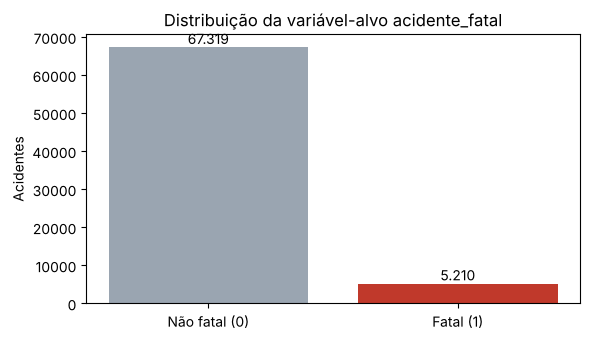

In [4]:
contagem_alvo = df["acidente_fatal"].value_counts().sort_index()
TAXA_GLOBAL = df["acidente_fatal"].mean()

tabela_alvo = pd.DataFrame({
    "classe": ["0 = não fatal", "1 = fatal"],
    "acidentes": contagem_alvo.values,
    "percentual": (contagem_alvo / contagem_alvo.sum()).round(4).values,
})
display(tabela_alvo)

print(f"Taxa global de fatalidade: {TAXA_GLOBAL:.2%}")
print(f"Para cada acidente fatal há cerca de {contagem_alvo[0] / contagem_alvo[1]:.0f} acidentes não fatais.")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Não fatal (0)", "Fatal (1)"], contagem_alvo.values, color=["#9aa5b1", "#c0392b"])
for i, valor in enumerate(contagem_alvo.values):
    ax.text(i, valor, f"{valor:,}".replace(",", "."), ha="center", va="bottom")
ax.set_title("Distribuição da variável-alvo acidente_fatal")
ax.set_ylabel("Acidentes")
plt.tight_layout()
plt.show()

**Leitura:** a base é **desbalanceada**. Os acidentes fatais são uma minoria. Guarde esta consequência, que volta no Bloco 3: um "modelo" que responde sempre "não fatal" já acerta mais de 92% dos casos sem ter aprendido nada.

### 1.2 Frequência não é risco

- **Frequência:** quantos acidentes uma categoria tem.
- **Risco (proporção):** qual percentual dos acidentes daquela categoria foi fatal.

Uma categoria pode ter muitos acidentes simplesmente por ser comum, sem ter proporção de fatalidade alta. A função abaixo calcula as duas leituras lado a lado, já com o **Lift** univariado (taxa da categoria dividida pela taxa global), que vamos formalizar no Bloco 4.

In [5]:
def tabela_risco(base, coluna, alvo="acidente_fatal", min_registros=100):
    # Frequência e risco de cada categoria de uma coluna
    tab = (base.groupby(coluna, observed=True)[alvo]
               .agg(registros="size", fatais="sum")
               .reset_index())
    tab["cobertura"] = tab["registros"] / len(base)
    tab["taxa_fatal"] = tab["fatais"] / tab["registros"]
    tab["lift"] = tab["taxa_fatal"] / base[alvo].mean()
    # Categorias com poucos registros geram percentuais instáveis
    return tab[tab["registros"] >= min_registros].round(4)


risco_tipo = tabela_risco(df, "tipo_acidente")

print("Top 5 tipos de acidente por FREQUÊNCIA")
display(risco_tipo.sort_values("registros", ascending=False).head(5))

print("Top 5 tipos de acidente por RISCO (taxa de fatalidade)")
display(risco_tipo.sort_values("taxa_fatal", ascending=False).head(5))

Top 5 tipos de acidente por FREQUÊNCIA


,tipo_acidente,registros,fatais,cobertura,taxa_fatal,lift
8,COLISÃO TRASEIRA,14360,619,0.1980,0.0431,0.6001
14,SAÍDA DE LEITO CARROÇÁVEL,10209,605,0.1408,0.0593,0.8250
7,COLISÃO TRANSVERSAL,9306,427,0.1283,0.0459,0.6388
5,COLISÃO LATERAL MESMO SENTIDO,7885,212,0.1087,0.0269,0.3743
16,TOMBAMENTO,6351,268,0.0876,0.0422,0.5874


Top 5 tipos de acidente por RISCO (taxa de fatalidade)


,tipo_acidente,registros,fatais,cobertura,taxa_fatal,lift
1,ATROPELAMENTO DE PEDESTRE,3057,902,0.0421,0.2951,4.1076
4,COLISÃO FRONTAL,4739,1396,0.0653,0.2946,4.1008
6,COLISÃO LATERAL SENTIDO OPOSTO,2152,212,0.0297,0.0985,1.3714
11,EVENTOS ATÍPICOS,287,23,0.0040,0.0801,1.1156
0,ATROPELAMENTO DE ANIMAL,1133,68,0.0156,0.0600,0.8355


> **Sua vez (discussão em dupla):** qual tipo de acidente é o mais frequente? Ele aparece entre os mais letais? Escreva um exemplo, com os números acima, em que frequência e risco levariam a conclusões diferentes.

*Resposta:*

### 1.3 Data leakage (vazamento de informação)

**Data leakage** acontece quando uma variável explicativa carrega informação do próprio desfecho. O modelo parece excelente, mas por um motivo inválido: ele recebeu a resposta disfarçada de pergunta.

Exemplo extremo: usar `mortos` para prever `acidente_fatal`. A árvore aprenderia "se mortos >= 1, então fatal", com 100% de acerto e nenhuma utilidade.

| Tratar como vazamento (fora de X) | Explicativas candidatas (podem entrar em X) |
|---|---|
| `mortos`, `feridos`, `feridos_leves`, `feridos_graves`, `ilesos`, `ignorados`, `total_vitimas`, `indice_gravidade`, `acidente_grave`, `classificacao_acidente` | `uf`, `br`, `municipio`, `causa_acidente`, `tipo_acidente`, `fase_dia`, `condicao_metereologica`, `tipo_pista`, `tracado_via`, `uso_solo`, mês, dia da semana, hora |

`classificacao_acidente` ("com vítimas fatais", "com vítimas feridas", "sem vítimas") é construída a partir de mortos e feridos. Por isso fica fora.

A base modelável do Módulo 4 já foi gerada sem essas colunas. Mesmo assim, a auditoria é obrigatória: bases mudam, colunas são renomeadas e um erro aqui invalida todo o módulo.

### Atividade prática 1 — Auditoria da base modelável

**Objetivo:** verificar se a base está adequada para modelagem e registrar, para cada variável, a decisão tomada e a justificativa.

In [6]:
# Passo 1: nenhuma coluna com vazamento pode estar na base
VARIAVEIS_COM_VAZAMENTO = ["mortos", "feridos", "feridos_leves", "feridos_graves",
                           "ilesos", "ignorados", "total_vitimas", "indice_gravidade",
                           "acidente_grave", "classificacao_acidente"]

presentes = [c for c in VARIAVEIS_COM_VAZAMENTO if c in df.columns]
print("Colunas com vazamento encontradas na base:", presentes if presentes else "nenhuma")
assert not presentes, "Remova estas colunas antes de seguir!"

# Passo 2: o alvo precisa ser binário (somente 0 e 1)
assert set(df["acidente_fatal"].unique()) == {0, 1}, "acidente_fatal deve conter apenas 0 e 1"
print("acidente_fatal confirmado como binário (0/1).")

Colunas com vazamento encontradas na base: nenhuma
acidente_fatal confirmado como binário (0/1).


In [7]:
# Passo 3: tabela de auditoria (variável, decisão, justificativa)
auditoria = pd.DataFrame([
    ("uf", "Manter", "Contexto geográfico; 27 categorias."),
    ("br_formatada", "Remover (testada no Bloco 5)", "115 categorias; no Bloco 5 entra agrupada nas BRs mais frequentes."),
    ("municipio", "Remover", "Mais de 1.800 categorias: geraria regras de poucos casos e difíceis de comunicar."),
    ("mes", "Manter (numérica)", "Sazonalidade; a árvore encontra faixas de meses sozinha."),
    ("trimestre", "Remover", "Redundante com mes."),
    ("dia_semana", "Manter", "Padrão semanal; categórica, pois os dias não têm ordem de intensidade."),
    ("dia_semana_num", "Remover", "Redundante com dia_semana."),
    ("fim_de_semana", "Manter", "Resumo binário legível de dia_semana (uma única pergunta na árvore)."),
    ("hora", "Manter (numérica)", "A árvore encontra os cortes de horário mais úteis."),
    ("faixa_horaria", "Remover", "Redundante com hora."),
    ("turno", "Remover", "Redundante com hora e fase_dia."),
    ("fase_dia", "Manter", "Luminosidade: pleno dia, plena noite, amanhecer, anoitecer."),
    ("causa_acidente", "Manter com cautela", "Causa presumida, registrada após o acidente; categorias raras são agrupadas."),
    ("tipo_acidente", "Manter com cautela", "Descreve a dinâmica do acidente, registrada após o fato."),
    ("condicao_metereologica", "Manter", "Condição ambiental."),
    ("tipo_pista", "Manter", "Simples, dupla ou múltipla."),
    ("tracado_via", "Transformar (Bloco 5)", "Texto em formato de lista com mais de 600 combinações; vira indicadores 0/1 no Bloco 5."),
    ("uso_solo", "Manter", "SIM = trecho urbano; NÃO = trecho rural."),
    ("acidente_fatal", "Alvo (y)", "Variável-alvo: 1 se mortos >= 1."),
], columns=["variavel", "decisao", "justificativa"])

# Confere se a auditoria cobre todas as colunas da base
faltando = set(df.columns) - set(auditoria["variavel"])
print("Colunas sem decisão registrada:", faltando if faltando else "nenhuma")

auditoria.to_csv(PASTA_RESULTADOS / "auditoria_base_modelavel_modulo7.csv",
                 sep=SEPARADOR, encoding=ENCODING, index=False)
auditoria

Colunas sem decisão registrada: nenhuma


,variavel,decisao,justificativa
0,uf,Manter,Contexto geográfico; 27 categorias.
1,br_formatada,Remover (testada no Bloco 5),115 categorias; no Bloco 5 entra agrupada nas BRs mais frequentes.
2,municipio,Remover,Mais de 1.800 categorias: geraria regras de poucos casos e difíceis de comunicar.
3,mes,Manter (numérica),Sazonalidade; a árvore encontra faixas de meses sozinha.
4,trimestre,Remover,Redundante com mes.
5,dia_semana,Manter,"Padrão semanal; categórica, pois os dias não têm ordem de intensidade."
6,dia_semana_num,Remover,Redundante com dia_semana.
7,fim_de_semana,Manter,Resumo binário legível de dia_semana (uma única pergunta na árvore).
8,hora,Manter (numérica),A árvore encontra os cortes de horário mais úteis.
9,faixa_horaria,Remover,Redundante com hora.


**Por que remover variáveis redundantes?** A árvore não "quebra" com redundância, mas ela escolhe arbitrariamente entre colunas que dizem a mesma coisa (`hora`, `faixa_horaria`, `turno`). As regras ficam mais confusas e a importância das variáveis se divide entre as cópias. Para explicabilidade, menos é mais.

**Por que "manter com cautela" para causa e tipo de acidente?** As duas são registradas pela PRF depois do acidente. Elas descrevem *como* o acidente aconteceu, não condições conhecidas *antes* dele. Para a pergunta "quais fatores estão associados à fatalidade?" elas são legítimas e foram usadas na EDA. Para um sistema que tentasse prever acidentes antes de acontecerem, não seriam. Essa distinção precisa aparecer nas limitações.

> **Sua vez:** você concorda com todas as decisões? Altere a tabela se discordar de alguma e justifique abaixo.

*Resposta:*

### 1.4 Separar X (explicativas) e y (alvo)

- **X**: tabela com as variáveis explicativas mantidas.
- **y**: a coluna `acidente_fatal`.

Separamos as explicativas em **categóricas** (texto) e **numéricas**, porque cada grupo recebe um tratamento diferente no Bloco 2.

In [8]:
COLUNAS_CATEGORICAS = ["uf", "causa_acidente", "tipo_acidente", "fase_dia",
                       "condicao_metereologica", "tipo_pista", "uso_solo", "dia_semana"]
COLUNAS_NUMERICAS = ["mes", "hora", "fim_de_semana"]
ALVO = "acidente_fatal"

X = df[COLUNAS_CATEGORICAS + COLUNAS_NUMERICAS].copy()
y = df[ALVO].copy()

# Checagem final: o alvo e as colunas com vazamento não podem estar em X
assert ALVO not in X.columns
assert not set(VARIAVEIS_COM_VAZAMENTO) & set(X.columns)

print("X:", X.shape, "| y:", y.shape)
print("Categóricas:", COLUNAS_CATEGORICAS)
print("Numéricas:  ", COLUNAS_NUMERICAS)

X: (72529, 11) | y: (72529,)
Categóricas: ['uf', 'causa_acidente', 'tipo_acidente', 'fase_dia', 'condicao_metereologica', 'tipo_pista', 'uso_solo', 'dia_semana']
Numéricas:   ['mes', 'hora', 'fim_de_semana']


## Bloco 2 — Árvore de decisão explicável

### O que é uma árvore de decisão?

É um modelo **supervisionado** (aprende com exemplos que já têm a resposta, o `y`) que divide os dados em grupos sucessivos fazendo perguntas simples sobre as variáveis.

```
                      [Todos os acidentes: 7% fatais]          <- nó raiz
                     /                               \
     tipo = colisão frontal?                       não          <- ramos
           /                                          \
 [29% fatais]                                    [6% fatais]    <- nós internos
     /       \                                     /      \
 noite?     dia?                                 ...      ...
   |          |
[folha]    [folha]                                              <- folhas
```

- **Nó raiz:** o grupo inicial, com todos os registros.
- **Nó interno:** uma pergunta ("tipo_pista é SIMPLES?").
- **Ramo:** a resposta (sim ou não), que leva ao próximo nó.
- **Folha:** um grupo final. O caminho da raiz até a folha é uma **regra**.

### Como a árvore escolhe as perguntas?

Ela testa todas as divisões possíveis e escolhe a que deixa os grupos resultantes mais **homogêneos** (menos misturados entre fatal e não fatal). A medida padrão de mistura no scikit-learn é o **índice de Gini**:

$$Gini = 1 - p_{fatal}^2 - p_{não\,fatal}^2$$

- Gini = 0: grupo puro (só fatais ou só não fatais).
- Gini = 0,5: mistura máxima (50% de cada).

Depois de uma divisão, calcula-se o Gini médio dos dois grupos, ponderado pelo tamanho de cada um. A melhor divisão é a que produz a **maior redução de Gini**. Outra medida possível é a **entropia** (`criterion="entropy"`), que costuma levar a árvores parecidas.

Vamos fazer esse cálculo à mão para algumas divisões candidatas.

In [9]:
def gini(proporcao_fatal):
    return 1 - proporcao_fatal ** 2 - (1 - proporcao_fatal) ** 2


def avaliar_divisao(base, coluna, categoria, alvo="acidente_fatal"):
    # Calcula a redução de Gini ao separar 'coluna == categoria' do restante
    mascara = base[coluna] == categoria
    sim, nao = base[mascara], base[~mascara]
    p_sim, p_nao = sim[alvo].mean(), nao[alvo].mean()
    gini_depois = (len(sim) * gini(p_sim) + len(nao) * gini(p_nao)) / len(base)
    return {
        "divisao": f"{coluna} = {categoria}",
        "registros_sim": len(sim),
        "taxa_fatal_sim": round(p_sim, 4),
        "taxa_fatal_nao": round(p_nao, 4),
        "gini_depois": round(gini_depois, 5),
        "reducao_gini": round(gini(base[alvo].mean()) - gini_depois, 5),
    }


print(f"Gini da raiz (antes de dividir): {gini(TAXA_GLOBAL):.5f}")

candidatas = [("tipo_acidente", "COLISÃO FRONTAL"),
              ("tipo_acidente", "ATROPELAMENTO DE PEDESTRE"),
              ("tipo_pista", "SIMPLES"),
              ("fase_dia", "PLENA NOITE"),
              ("uso_solo", "NÃO")]

comparacao_divisoes = (pd.DataFrame([avaliar_divisao(df, c, v) for c, v in candidatas])
                         .sort_values("reducao_gini", ascending=False))
comparacao_divisoes

Gini da raiz (antes de dividir): 0.13335


,divisao,registros_sim,taxa_fatal_sim,taxa_fatal_nao,gini_depois,reducao_gini
0,tipo_acidente = COLISÃO FRONTAL,4739,0.2946,0.0563,0.12641,0.00694
1,tipo_acidente = ATROPELAMENTO DE PEDESTRE,3057,0.2951,0.0620,0.12896,0.00439
2,tipo_pista = SIMPLES,34733,0.0986,0.0473,0.13203,0.00131
4,uso_solo = NÃO,41444,0.0911,0.0462,0.13236,0.00099
3,fase_dia = PLENA NOITE,24781,0.1018,0.0563,0.13242,0.00093


**Leitura:** a divisão do topo da tabela é a que mais "limpa" a mistura entre fatal e não fatal entre essas cinco. A árvore faz este mesmo cálculo para **todas** as variáveis e categorias e escolhe a melhor. No passo 2.4 vamos conferir qual pergunta ela escolheu para a raiz.

Repare que uma divisão pode ter taxa de fatalidade alta no grupo "sim" e ainda assim reduzir pouco o Gini, se o grupo for pequeno. A árvore equilibra força e tamanho, a mesma tensão entre Lift e Cobertura que veremos no Bloco 4.

### 2.2 Codificação das variáveis categóricas (One-Hot Encoding)

A árvore do scikit-learn só trabalha com números. Variáveis de texto, como `tipo_pista`, precisam ser convertidas. O **One-Hot Encoding** cria uma coluna 0/1 para cada categoria:

In [10]:
exemplo = df[["tipo_pista"]].head(6)
print("Antes da codificação:")
display(exemplo)

print("Depois da codificação (uma coluna 0/1 por categoria):")
display(pd.get_dummies(exemplo, prefix_sep="==", dtype=int))

Antes da codificação:


,tipo_pista
0,MÚLTIPLA
1,SIMPLES
2,DUPLA
3,DUPLA
4,SIMPLES
5,SIMPLES


Depois da codificação (uma coluna 0/1 por categoria):


,tipo_pista==DUPLA,tipo_pista==MÚLTIPLA,tipo_pista==SIMPLES
0,0,1,0
1,0,0,1
2,1,0,0
3,1,0,0
4,0,0,1
5,0,0,1


Na árvore, a pergunta sobre a coluna `tipo_pista==SIMPLES` aparece como `tipo_pista==SIMPLES <= 0.5`:
- **verdadeiro (ramo da esquerda)**: o valor é 0, ou seja, a pista **não** é simples;
- **falso (ramo da direita)**: o valor é 1, ou seja, a pista **é** simples.

No pipeline usamos o `OneHotEncoder` do scikit-learn, em vez do `pd.get_dummies`, por três motivos:

1. **Aprende as categorias só no treino** e aplica a mesma transformação no teste, sem espiar os dados de avaliação.
2. **Agrupa categorias raras** (`min_frequency=100`): categorias com menos de 100 registros no treino viram uma única coluna "infrequente". Isso evita regras baseadas em pouquíssimos casos. Nas regras, elas aparecem como `OUTRAS (agrupadas)`.
3. **Não quebra com categorias novas**: se o teste trouxer uma categoria nunca vista, ela é tratada como infrequente.

As variáveis numéricas (`mes`, `hora`, `fim_de_semana`) passam direto (`passthrough`). A árvore não precisa de padronização ou normalização, porque só compara valores com limites ("hora <= 5,5?").

In [11]:
def combinar_nome(variavel, categoria):
    # Nome da coluna codificada: 'variavel==categoria' (facilita traduzir as regras depois)
    return f"{variavel}=={categoria}"


def criar_preprocessador(colunas_categoricas, colunas_numericas, min_frequencia=100):
    codificador = OneHotEncoder(handle_unknown="infrequent_if_exist",
                                min_frequency=min_frequencia,
                                sparse_output=False,
                                feature_name_combiner=combinar_nome)
    return ColumnTransformer(
        [("cat", codificador, colunas_categoricas),
         ("num", "passthrough", colunas_numericas)],
        verbose_feature_names_out=False,
    )


def criar_arvore(**parametros):
    # Pipeline = pré-processamento + árvore, sempre treinados juntos
    return Pipeline([
        ("prep", criar_preprocessador(COLUNAS_CATEGORICAS, COLUNAS_NUMERICAS)),
        ("arvore", DecisionTreeClassifier(random_state=SEMENTE, **parametros)),
    ])

### 2.3 Separação treino/teste

Se avaliarmos o modelo nos mesmos dados usados para treiná-lo, ele parece melhor do que é, como um aluno que decorou a prova. Por isso dividimos a base:

- **Treino (70%)**: a árvore aprende as divisões.
- **Teste (30%)**: dados que a árvore nunca viu, usados só para avaliar.

O parâmetro `stratify=y` mantém a mesma proporção de acidentes fatais nos dois conjuntos. Em bases desbalanceadas isso é essencial: sem estratificação, por azar, o teste poderia ficar com poucos fatais.

In [12]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEMENTE)

pd.DataFrame({
    "conjunto": ["treino", "teste"],
    "registros": [len(X_treino), len(X_teste)],
    "fatais": [y_treino.sum(), y_teste.sum()],
    "taxa_fatal": [round(y_treino.mean(), 4), round(y_teste.mean(), 4)],
})

,conjunto,registros,fatais,taxa_fatal
0,treino,50770,3647,0.0718
1,teste,21759,1563,0.0718


### Atividade prática 2 — Treinar a primeira árvore

**Objetivo:** treinar uma árvore simples para classificar `acidente_fatal` e visualizá-la.

Começamos com uma árvore **rasa** e controlada, porque o foco é a leitura das regras:

| Parâmetro | Valor | O que controla |
|---|---|---|
| `max_depth` | 3 | Profundidade máxima: no máximo 3 perguntas até uma folha (até 8 folhas). |
| `min_samples_leaf` | 200 | Toda folha precisa ter pelo menos 200 acidentes. Evita regras de grupos minúsculos. |
| `min_samples_split` | padrão (2) | Mínimo de registros para um nó poder ser dividido. |
| `class_weight` | padrão (None) | Peso das classes. Fica para o Bloco 3. |

In [13]:
arvore_v1 = criar_arvore(max_depth=3, min_samples_leaf=200)
arvore_v1.fit(X_treino, y_treino)

modelo_v1 = arvore_v1.named_steps["arvore"]
colunas_codificadas = arvore_v1.named_steps["prep"].get_feature_names_out()

print("Colunas depois da codificação:", len(colunas_codificadas))
print("Profundidade da árvore:", modelo_v1.get_depth())
print("Número de folhas (regras):", modelo_v1.get_n_leaves())
print("Pergunta escolhida para a raiz:", colunas_codificadas[modelo_v1.tree_.feature[0]])

Colunas depois da codificação: 114
Profundidade da árvore: 3
Número de folhas (regras): 8
Pergunta escolhida para a raiz: tipo_acidente==COLISÃO FRONTAL


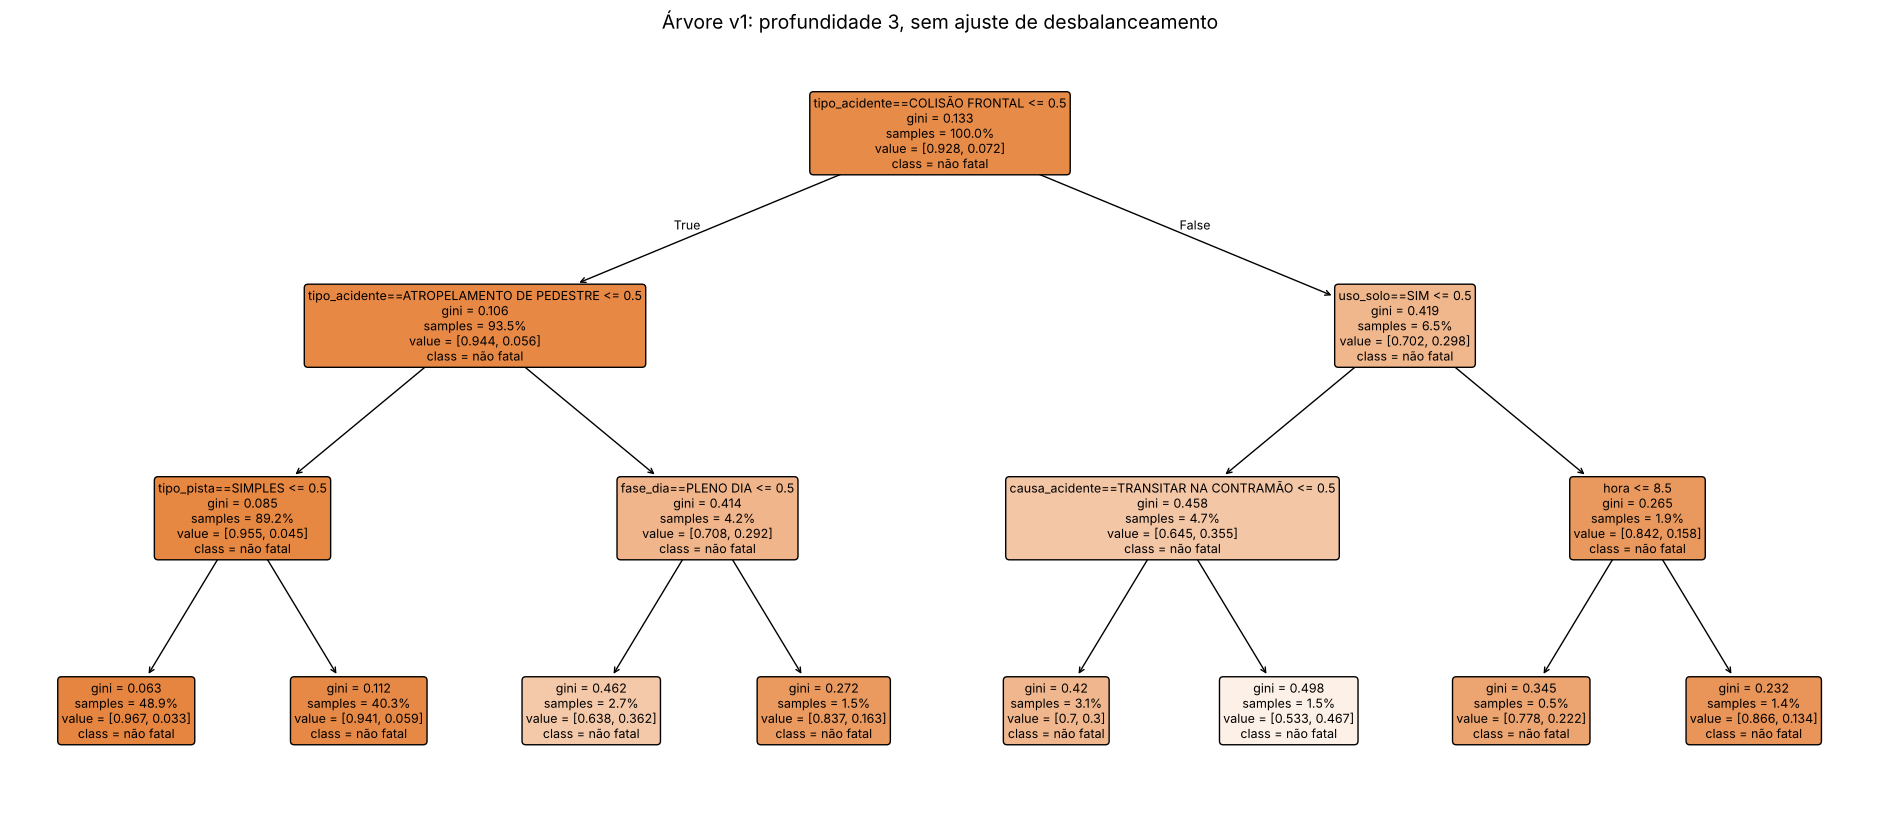

In [14]:
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(modelo_v1,
          feature_names=list(colunas_codificadas),
          class_names=["não fatal", "fatal"],
          filled=True, rounded=True, impurity=True, proportion=True,
          fontsize=9, ax=ax)
ax.set_title("Árvore v1: profundidade 3, sem ajuste de desbalanceamento", fontsize=14)
plt.show()

**Como ler cada caixa:**

- **1ª linha:** a pergunta. Ex.: `tipo_acidente==COLISÃO FRONTAL <= 0.5` significa "o acidente **não** é colisão frontal?". Verdadeiro vai para a esquerda, falso para a direita.
- **gini:** a mistura do grupo (quanto menor, mais homogêneo).
- **samples:** a fração dos registros de treino que chegou a este nó.
- **value:** a proporção [não fatal, fatal] dentro do nó. O segundo número é a **taxa de fatalidade do grupo**.
- **class:** a classe majoritária do nó, ou seja, o que a árvore preveria ali.
- **Cor:** laranja indica maioria não fatal; azul, maioria fatal. Quanto mais forte, mais puro o grupo.

A mesma árvore pode ser impressa em texto, o que facilita copiar as regras:

In [15]:
print(export_text(modelo_v1, feature_names=list(colunas_codificadas), show_weights=True))

|--- tipo_acidente==COLISÃO FRONTAL <= 0.50
|   |--- tipo_acidente==ATROPELAMENTO DE PEDESTRE <= 0.50
|   |   |--- tipo_pista==SIMPLES <= 0.50
|   |   |   |--- weights: [24016.00, 810.00] class: 0
|   |   |--- tipo_pista==SIMPLES >  0.50
|   |   |   |--- weights: [19252.00, 1216.00] class: 0
|   |--- tipo_acidente==ATROPELAMENTO DE PEDESTRE >  0.50
|   |   |--- fase_dia==PLENO DIA <= 0.50
|   |   |   |--- weights: [890.00, 506.00] class: 0
|   |   |--- fase_dia==PLENO DIA >  0.50
|   |   |   |--- weights: [633.00, 123.00] class: 0
|--- tipo_acidente==COLISÃO FRONTAL >  0.50
|   |--- uso_solo==SIM <= 0.50
|   |   |--- causa_acidente==TRANSITAR NA CONTRAMÃO <= 0.50
|   |   |   |--- weights: [1115.00, 478.00] class: 0
|   |   |--- causa_acidente==TRANSITAR NA CONTRAMÃO >  0.50
|   |   |   |--- weights: [415.00, 364.00] class: 0
|   |--- uso_solo==SIM >  0.50
|   |   |--- hora <= 8.50
|   |   |   |--- weights: [200.00, 57.00] class: 0
|   |   |--- hora >  8.50
|   |   |   |--- weights: [60

> **Sua vez:** a pergunta da raiz coincide com a melhor divisão do seu cálculo manual de Gini (2.1)? Por que a árvore pode ter escolhido outra pergunta? (Dica: ela testa todas as categorias de todas as variáveis.) Repare também na linha `class` das folhas: quantas preveem "fatal"? Guarde essa observação para o Bloco 3.

*Resposta:*

## Bloco 3 — Métricas de classificação

### Matriz de confusão em linguagem simples

Classe positiva = **fatal (1)**.

| | Previsto: não fatal (0) | Previsto: fatal (1) |
|---|---|---|
| **Real: não fatal (0)** | Verdadeiro Negativo (VN) | Falso Positivo (FP): alarme falso |
| **Real: fatal (1)** | Falso Negativo (FN): fatal que passou despercebido | Verdadeiro Positivo (VP) |

### As métricas

| Métrica | Fórmula | Pergunta que responde |
|---|---|---|
| Acurácia | (VP + VN) / total | Quanto o modelo acerta no geral? **Engana em bases desbalanceadas.** |
| Precisão | VP / (VP + FP) | Dos acidentes que o modelo apontou como fatais, quantos eram de fato? |
| Recall (sensibilidade) | VP / (VP + FN) | Dos acidentes fatais reais, quantos o modelo encontrou? |
| F1-score | 2 × Precisão × Recall / (Precisão + Recall) | Equilíbrio entre precisão e recall. |
| ROC-AUC | área sob a curva ROC | Quão bem o modelo **ordena** os casos (fatais acima dos não fatais), sem depender de um limiar. 0,5 = sorteio. |
| PR-AUC (Average Precision) | área sob a curva Precisão-Recall | Parecida com a ROC-AUC, mas focada na classe rara. O valor de referência é a própria taxa de fatais (cerca de 0,07). |

### Linha de base: o "modelo preguiçoso"

Antes de avaliar a árvore, criamos um modelo que sempre responde a classe mais comum (`DummyClassifier`). Qualquer modelo útil precisa superar essa referência nas métricas que importam.

In [16]:
def calcular_metricas(modelo, X_aval, y_aval, nome, limiar=0.5):
    # Probabilidade estimada de 'fatal' e classe prevista para um limiar
    proba = modelo.predict_proba(X_aval)[:, 1]
    previsto = (proba >= limiar).astype(int)
    return {
        "modelo": nome,
        "acuracia": accuracy_score(y_aval, previsto),
        "precisao": precision_score(y_aval, previsto, zero_division=0),
        "recall": recall_score(y_aval, previsto, zero_division=0),
        "f1": f1_score(y_aval, previsto, zero_division=0),
        "roc_auc": roc_auc_score(y_aval, proba),
        "pr_auc": average_precision_score(y_aval, proba),
    }


modelo_preguicoso = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)

tabela_metricas = pd.DataFrame([
    calcular_metricas(modelo_preguicoso, X_teste, y_teste, "Linha de base (sempre 'não fatal')"),
    calcular_metricas(arvore_v1, X_teste, y_teste, "Árvore v1 (prof. 3, sem pesos)"),
]).round(4)
tabela_metricas

,modelo,acuracia,precisao,recall,f1,roc_auc,pr_auc
0,Linha de base (sempre 'não fatal'),0.9282,0.0,0.0,0.0,0.5000,0.0718
1,"Árvore v1 (prof. 3, sem pesos)",0.9282,0.0,0.0,0.0,0.7214,0.2199


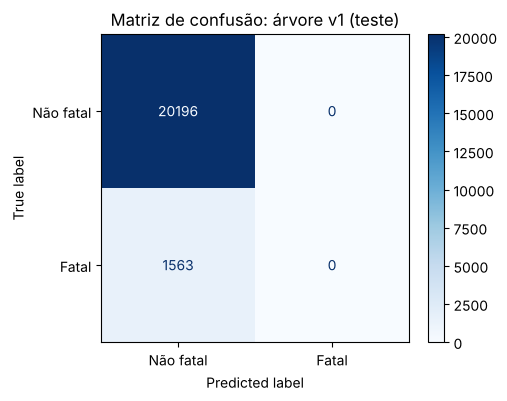

Acidentes fatais no teste: 1563
Encontrados pela árvore v1 (VP): 0  |  Não encontrados (FN): 1563
Alarmes falsos (FP): 0

               precision    recall  f1-score   support

não fatal (0)      0.928     1.000     0.963     20196
    fatal (1)      0.000     0.000     0.000      1563

     accuracy                          0.928     21759
    macro avg      0.464     0.500     0.481     21759
 weighted avg      0.861     0.928     0.894     21759



In [17]:
previsto_v1 = arvore_v1.predict(X_teste)
vn, fp, fn, vp = confusion_matrix(y_teste, previsto_v1).ravel()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_teste, previsto_v1, display_labels=["Não fatal", "Fatal"],
                                        cmap="Blues", values_format="d", ax=ax)
ax.set_title("Matriz de confusão: árvore v1 (teste)")
plt.show()

print(f"Acidentes fatais no teste: {vp + fn}")
print(f"Encontrados pela árvore v1 (VP): {vp}  |  Não encontrados (FN): {fn}")
print(f"Alarmes falsos (FP): {fp}")
print()
print(classification_report(y_teste, previsto_v1, target_names=["não fatal (0)", "fatal (1)"],
                            digits=3, zero_division=0))

### Atividade prática 3 — Avaliar o modelo

**Leitura esperada:** a acurácia da árvore v1 é igual (ou quase igual) à do modelo preguiçoso, e o recall da classe fatal é zero ou perto disso. A árvore aprendeu que, em todos os grupos, a maioria dos acidentes **não** é fatal. Isso é verdade, mas não ajuda a encontrar os fatais. Como cada folha prevê a classe majoritária, e nenhuma folha tem maioria fatal (confira a linha `class` no gráfico), a previsão é sempre "não fatal".

Isso não quer dizer que a árvore v1 seja inútil para **explicar**: as folhas continuam separando grupos com taxas de fatalidade bem diferentes (veja a linha `value` no gráfico e a ROC-AUC acima de 0,5). A previsão de classe é que fica presa à maioria.

> **Sua vez (discussão em grupo):** num projeto de segurança viária, o que é mais grave, um falso positivo ou um falso negativo? Justifique. Depois, responda: o modelo identifica bem os acidentes fatais? A acurácia é suficiente para confiar nele?

*Resposta:*

### 3.2 Lidando com o desbalanceamento: `class_weight="balanced"`

Com `class_weight="balanced"`, cada acidente fatal passa a "pesar" mais no treino, na proporção inversa da sua frequência. Na prática, a árvore passa a se importar tanto com errar um fatal quanto com errar muitos não fatais:

In [18]:
n_total, n_fatal = len(y_treino), y_treino.sum()
peso_fatal = n_total / (2 * n_fatal)
peso_nao_fatal = n_total / (2 * (n_total - n_fatal))
print(f"Peso de cada acidente NÃO fatal: {peso_nao_fatal:.2f}")
print(f"Peso de cada acidente FATAL:     {peso_fatal:.2f}  (cerca de {peso_fatal / peso_nao_fatal:.0f} vezes maior)")

Peso de cada acidente NÃO fatal: 0.54
Peso de cada acidente FATAL:     6.96  (cerca de 13 vezes maior)


Treinamos a **árvore v2**, que será a nossa **árvore explicável** para as regras do Bloco 4:

- `max_depth=4`: até 16 regras, ainda legíveis;
- `min_samples_leaf=300`: toda regra cobre pelo menos 300 acidentes do treino;
- `class_weight="balanced"`.

Folhas da árvore v2: 14


,modelo,acuracia,precisao,recall,f1,roc_auc,pr_auc
0,Linha de base (sempre 'não fatal'),0.9282,0.0000,0.0000,0.0000,0.5000,0.0718
1,"Árvore v1 (prof. 3, sem pesos)",0.9282,0.0000,0.0000,0.0000,0.7214,0.2199
2,"Árvore v2 (prof. 4, balanced)",0.6462,0.1337,0.7166,0.2254,0.7455,0.2364


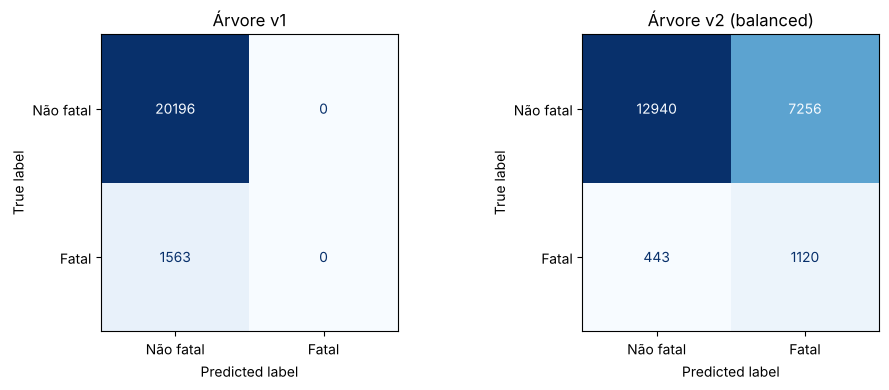

In [19]:
arvore_v2 = criar_arvore(max_depth=4, min_samples_leaf=300, class_weight="balanced")
arvore_v2.fit(X_treino, y_treino)
modelo_v2 = arvore_v2.named_steps["arvore"]
print("Folhas da árvore v2:", modelo_v2.get_n_leaves())

tabela_metricas = pd.DataFrame([
    calcular_metricas(modelo_preguicoso, X_teste, y_teste, "Linha de base (sempre 'não fatal')"),
    calcular_metricas(arvore_v1, X_teste, y_teste, "Árvore v1 (prof. 3, sem pesos)"),
    calcular_metricas(arvore_v2, X_teste, y_teste, "Árvore v2 (prof. 4, balanced)"),
]).round(4)
display(tabela_metricas)

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
for ax, modelo, titulo in [(eixos[0], arvore_v1, "Árvore v1"), (eixos[1], arvore_v2, "Árvore v2 (balanced)")]:
    ConfusionMatrixDisplay.from_predictions(y_teste, modelo.predict(X_teste),
                                            display_labels=["Não fatal", "Fatal"],
                                            cmap="Blues", values_format="d", ax=ax, colorbar=False)
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

In [20]:
m1 = tabela_metricas.set_index("modelo").iloc[1]
m2 = tabela_metricas.set_index("modelo").iloc[2]
print(f"Recall (fatais encontrados): v1 = {m1['recall']:.1%}  ->  v2 = {m2['recall']:.1%}")
print(f"Precisão (acerto quando aponta 'fatal'): v1 = {m1['precisao']:.1%}  ->  v2 = {m2['precisao']:.1%}")
print(f"Acurácia: v1 = {m1['acuracia']:.1%}  ->  v2 = {m2['acuracia']:.1%}")

Recall (fatais encontrados): v1 = 0.0%  ->  v2 = 71.7%
Precisão (acerto quando aponta 'fatal'): v1 = 0.0%  ->  v2 = 13.4%
Acurácia: v1 = 92.8%  ->  v2 = 64.6%


**Leitura:** a v2 troca acurácia por recall. Ela passa a encontrar boa parte dos acidentes fatais, ao custo de muitos alarmes falsos (precisão baixa). Essa troca é esperada quando a classe positiva é rara.

Para o nosso objetivo, explicar padrões e não automatizar decisões, a v2 é mais útil: suas folhas são construídas para isolar grupos onde os fatais se concentram.

### 3.3 Curvas ROC e Precisão-Recall

As métricas acima dependem de um **limiar** (por padrão, 0,5): se a probabilidade estimada de fatal for maior ou igual ao limiar, a previsão é "fatal". As curvas mostram o desempenho para **todos** os limiares de uma vez.

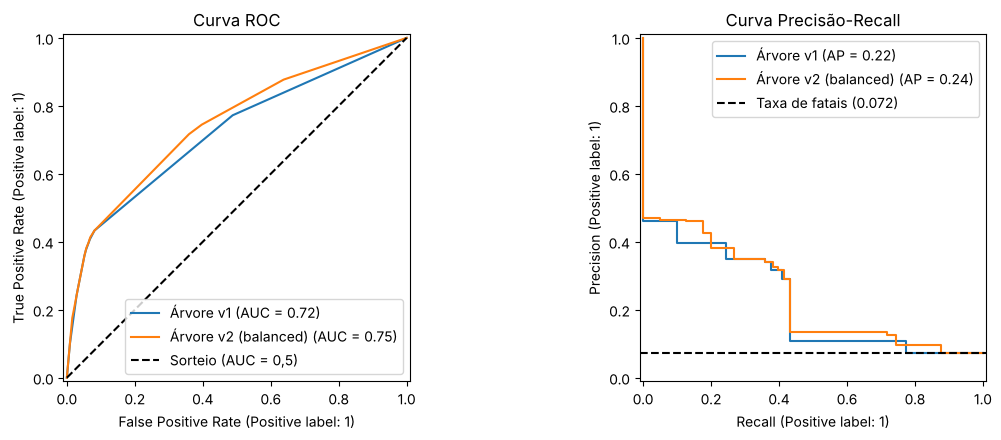

In [21]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
for modelo, nome in [(arvore_v1, "Árvore v1"), (arvore_v2, "Árvore v2 (balanced)")]:
    RocCurveDisplay.from_estimator(modelo, X_teste, y_teste, name=nome, ax=eixos[0])
    PrecisionRecallDisplay.from_estimator(modelo, X_teste, y_teste, name=nome, ax=eixos[1])
eixos[0].plot([0, 1], [0, 1], "k--", label="Sorteio (AUC = 0,5)")
eixos[0].set_title("Curva ROC")
eixos[0].legend(loc="lower right")
eixos[1].axhline(y_teste.mean(), color="k", linestyle="--", label=f"Taxa de fatais ({y_teste.mean():.3f})")
eixos[1].set_title("Curva Precisão-Recall")
eixos[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

**Como ler:**

- **ROC:** quanto mais a curva se afasta da diagonal tracejada (sorteio) em direção ao canto superior esquerdo, melhor o modelo ordena fatais acima de não fatais.
- **Precisão-Recall:** a linha tracejada é a precisão de quem chuta "fatal" para tudo, igual à taxa de fatais. Tudo acima dela é ganho real. Em classes raras, esta curva é mais honesta que a ROC.

As duas árvores têm curvas em "degraus" porque uma árvore rasa só produz poucos valores de probabilidade, um por folha.

### 3.4 Escolhendo o limiar de decisão

Mudar o limiar não exige treinar de novo: só muda a partir de qual probabilidade chamamos um caso de "fatal". Limiar mais baixo aumenta o recall e reduz a precisão; limiar mais alto faz o contrário.

,limiar,apontados_como_fatais,precisao,recall,f1
0,0.3,14253,0.096,0.877,0.173
1,0.4,9182,0.127,0.745,0.217
2,0.5,8376,0.134,0.717,0.225
3,0.6,2320,0.292,0.433,0.349
4,0.7,1904,0.326,0.397,0.358
5,0.8,1609,0.349,0.360,0.354


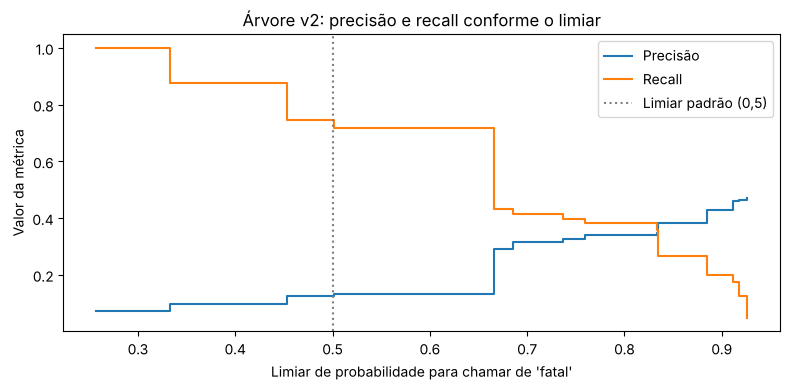

In [22]:
proba_v2 = arvore_v2.predict_proba(X_teste)[:, 1]

linhas = []
for limiar in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    previsto = (proba_v2 >= limiar).astype(int)
    linhas.append({
        "limiar": limiar,
        "apontados_como_fatais": int(previsto.sum()),
        "precisao": round(precision_score(y_teste, previsto, zero_division=0), 3),
        "recall": round(recall_score(y_teste, previsto, zero_division=0), 3),
        "f1": round(f1_score(y_teste, previsto, zero_division=0), 3),
    })
display(pd.DataFrame(linhas))

precisoes, recalls, limiares = precision_recall_curve(y_teste, proba_v2)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(limiares, precisoes[:-1], label="Precisão", drawstyle="steps-post")
ax.plot(limiares, recalls[:-1], label="Recall", drawstyle="steps-post")
ax.axvline(0.5, color="gray", linestyle=":", label="Limiar padrão (0,5)")
ax.set_xlabel("Limiar de probabilidade para chamar de 'fatal'")
ax.set_ylabel("Valor da métrica")
ax.set_title("Árvore v2: precisão e recall conforme o limiar")
ax.legend()
plt.tight_layout()
plt.show()

**Cuidado importante:** com `class_weight="balanced"`, a "probabilidade" que a árvore devolve **não é** a taxa real de fatalidade do grupo, porque os fatais foram inflados no treino. Como cada fatal pesou cerca de 13 vezes mais, uma folha que mostra 0,6 de "probabilidade" tem, na realidade, só cerca de 10% de acidentes fatais.

Por isso, no Bloco 4, as taxas das regras são calculadas **contando os acidentes reais** de cada folha, e não lidas da árvore.

> **Sua vez:** qual limiar você escolheria se o objetivo fosse priorizar trechos para fiscalização, com equipes limitadas? E se fosse não deixar escapar quase nenhum caso grave? Justifique com a tabela.

*Resposta:*

## Bloco 4 — Da árvore às regras SE-ENTÃO

Cada caminho da raiz até uma folha é uma **regra**:

> SE `tipo_acidente = COLISÃO FRONTAL` E `tipo_pista = SIMPLES` ENTÃO maior proporção de acidentes fatais

Nem toda regra é útil. Para avaliá-las usamos três medidas, todas comparadas com a **taxa global**:

| Medida | Fórmula | O que diz |
|---|---|---|
| **Taxa global** | acidentes fatais / total de acidentes | A régua de comparação (cerca de 7%). |
| **Cobertura** | registros da regra / total de registros | O **tamanho** do grupo. Regra com cobertura minúscula pode ser acaso. |
| **Confiança** | acidentes fatais da regra / registros da regra | A **taxa de fatalidade** dentro do grupo. |
| **Lift** | confiança da regra / taxa global | Quantas vezes o grupo está **acima (ou abaixo) da média**. |

- **Lift > 1:** grupo com proporção de fatais acima da média (Lift 2 = o dobro da média).
- **Lift = 1:** igual à média, a regra não acrescenta nada.
- **Lift < 1:** abaixo da média, um grupo de risco relativo menor.

### Exemplo calculado à mão

In [23]:
regra_exemplo = (df["tipo_acidente"] == "COLISÃO FRONTAL") & (df["tipo_pista"] == "SIMPLES")

registros = int(regra_exemplo.sum())
fatais = int(df.loc[regra_exemplo, "acidente_fatal"].sum())
cobertura = registros / len(df)
confianca = fatais / registros
lift = confianca / TAXA_GLOBAL

print("Regra: SE tipo_acidente = COLISÃO FRONTAL E tipo_pista = SIMPLES")
print(f"  Registros da regra: {registros}  |  Fatais na regra: {fatais}")
print(f"  Cobertura = {registros} / {len(df)} = {cobertura:.2%}")
print(f"  Confiança = {fatais} / {registros} = {confianca:.2%}")
print(f"  Lift      = {confianca:.2%} / {TAXA_GLOBAL:.2%} = {lift:.2f}")
print(f"Leitura: neste grupo a proporção de acidentes fatais é {lift:.1f} vezes a média da base.")

Regra: SE tipo_acidente = COLISÃO FRONTAL E tipo_pista = SIMPLES
  Registros da regra: 4236  |  Fatais na regra: 1325
  Cobertura = 4236 / 72529 = 5.84%
  Confiança = 1325 / 4236 = 31.28%
  Lift      = 31.28% / 7.18% = 4.35
Leitura: neste grupo a proporção de acidentes fatais é 4.4 vezes a média da base.


### Alto Lift não basta

Uma boa regra equilibra:

- **Lift relevante**, claramente acima de 1;
- **Cobertura mínima**, para não ser um grupo de meia dúzia de casos;
- **Estabilidade**: a taxa se mantém em dados que a árvore não viu (o teste);
- **Interpretação clara e coerência com o domínio**;
- **Utilidade**: pode orientar uma investigação ou ação.

Evite regras com poucos casos, regras óbvias, regras impossíveis de acionar, regras com vazamento e conclusões causais.

### Atividade prática 4 — Extrair e ranquear regras

Vamos programar três funções:

1. `extrair_regras`: percorre a árvore e guarda, para cada folha, a lista de condições do caminho;
2. `condicoes_para_texto`: traduz as condições técnicas (`tipo_pista==SIMPLES > 0.5`) para linguagem legível (`tipo_pista = SIMPLES`). Quando a regra exclui categorias e sobram poucas, ela diz quais sobram: `uso_solo ≠ SIM` vira `uso_solo = NÃO`;
3. `tabela_de_regras`: conta os acidentes reais em cada folha e calcula Cobertura, Confiança e Lift no **treino** e no **teste**.

In [24]:
def extrair_regras(pipeline):
    # Devolve {id_da_folha: [(coluna, operador, limite), ...]} percorrendo a árvore
    arvore = pipeline.named_steps["arvore"].tree_
    nomes = pipeline.named_steps["prep"].get_feature_names_out()
    regras = {}

    def percorrer(no, condicoes):
        esquerda, direita = arvore.children_left[no], arvore.children_right[no]
        if esquerda == direita:  # nó sem filhos = folha
            regras[no] = condicoes
            return
        coluna, limite = nomes[arvore.feature[no]], arvore.threshold[no]
        percorrer(esquerda, condicoes + [(coluna, "<=", limite)])
        percorrer(direita, condicoes + [(coluna, ">", limite)])

    percorrer(0, [])
    return regras


def categorias_conhecidas(pipeline):
    # {variavel: [categorias]} das variáveis categóricas SEM categorias raras agrupadas
    prep = pipeline.named_steps["prep"]
    codificador = prep.named_transformers_["cat"]
    colunas = prep.transformers_[0][2]
    return {var: list(cats) for var, cats, raras in
            zip(colunas, codificador.categories_, codificador.infrequent_categories_) if raras is None}


def condicoes_para_texto(condicoes, categorias=None):
    # Agrupa as condições por variável e escreve a regra em linguagem legível
    categorias = categorias or {}
    por_variavel = {}
    for coluna, operador, limite in condicoes:
        if "==" in coluna:  # coluna criada pelo One-Hot Encoding
            variavel, categoria = coluna.split("==", 1)
            if categoria == "infrequent_sklearn":
                categoria = "OUTRAS (agrupadas)"
            info = por_variavel.setdefault(variavel, {"igual": None, "diferente": [], "min": None, "max": None})
            if operador == ">":
                info["igual"] = categoria       # valor 1: É a categoria
            else:
                info["diferente"].append(categoria)  # valor 0: NÃO é a categoria
        else:  # variável numérica inteira (mes, hora, fim_de_semana, indicadores 0/1)
            info = por_variavel.setdefault(coluna, {"igual": None, "diferente": [], "min": None, "max": None})
            if operador == "<=":
                corte = int(np.floor(limite))
                info["max"] = corte if info["max"] is None else min(info["max"], corte)
            else:
                corte = int(np.floor(limite)) + 1
                info["min"] = corte if info["min"] is None else max(info["min"], corte)

    partes = []
    for variavel, info in por_variavel.items():
        if info["igual"] is not None:
            partes.append(f"{variavel} = {info['igual']}")
        elif info["diferente"]:
            cats = info["diferente"]
            # Se sobram poucas categorias, é mais claro dizer quais SÃO (ex.: uso_solo ≠ SIM -> uso_solo = NÃO)
            restantes = [c for c in categorias.get(variavel, []) if c not in cats]
            if len(restantes) == 1:
                partes.append(f"{variavel} = {restantes[0]}")
            elif 1 < len(restantes) <= 3:
                partes.append(f"{variavel} é {', '.join(restantes[:-1])} ou {restantes[-1]}")
            elif len(cats) == 1:
                partes.append(f"{variavel} ≠ {cats[0]}")
            else:
                partes.append(f"{variavel} não é {', '.join(cats[:-1])} nem {cats[-1]}")
        minimo, maximo = info["min"], info["max"]
        if minimo is not None and maximo is not None:
            partes.append(f"{variavel} = {minimo}" if minimo == maximo else f"{minimo} ≤ {variavel} ≤ {maximo}")
        elif minimo is not None:
            partes.append(f"{variavel} ≥ {minimo}")
        elif maximo is not None:
            partes.append(f"{variavel} ≤ {maximo}")
    return " E ".join(partes) if partes else "(todos os acidentes)"


def contar_por_folha(pipeline, X_ref, y_ref):
    # Conta registros e fatais REAIS em cada folha (não usa as probabilidades da árvore)
    folhas = pipeline.named_steps["arvore"].apply(pipeline.named_steps["prep"].transform(X_ref))
    return (pd.DataFrame({"folha": folhas, "fatal": y_ref.to_numpy()})
              .groupby("folha")["fatal"].agg(registros="size", fatais="sum"))


def tabela_de_regras(pipeline, X_tr, y_tr, X_te, y_te):
    regras = extrair_regras(pipeline)
    categorias = categorias_conhecidas(pipeline)
    treino = contar_por_folha(pipeline, X_tr, y_tr)
    teste = contar_por_folha(pipeline, X_te, y_te)
    taxa_tr, taxa_te = y_tr.mean(), y_te.mean()

    linhas = []
    for folha, condicoes in regras.items():
        reg = treino.loc[folha, "registros"] if folha in treino.index else 0
        fat = treino.loc[folha, "fatais"] if folha in treino.index else 0
        reg_te = teste.loc[folha, "registros"] if folha in teste.index else 0
        fat_te = teste.loc[folha, "fatais"] if folha in teste.index else 0
        conf = fat / reg if reg else np.nan
        conf_te = fat_te / reg_te if reg_te else np.nan
        linhas.append({
            "folha": folha,
            "regra": condicoes_para_texto(condicoes, categorias),
            "n_condicoes": len(condicoes),
            "registros": int(reg),
            "fatais": int(fat),
            "cobertura": reg / len(y_tr),
            "confianca": conf,
            "lift": conf / taxa_tr,
            "registros_teste": int(reg_te),
            "confianca_teste": conf_te,
            "lift_teste": conf_te / taxa_te,
        })
    return pd.DataFrame(linhas).sort_values("lift", ascending=False).reset_index(drop=True)

In [25]:
regras_v2 = tabela_de_regras(arvore_v2, X_treino, y_treino, X_teste, y_teste)

# Conferência: as folhas somam todos os registros e todos os fatais do treino
assert regras_v2["registros"].sum() == len(y_treino)
assert regras_v2["fatais"].sum() == y_treino.sum()

print(f"Total de regras (folhas) da árvore v2: {len(regras_v2)}")
print(f"Taxa global no treino: {y_treino.mean():.2%}")
regras_v2.round(4)

Total de regras (folhas) da árvore v2: 14
Taxa global no treino: 7.18%


,folha,regra,n_condicoes,registros,fatais,cobertura,confianca,lift,registros_teste,confianca_teste,lift_teste
0,26,tipo_acidente = COLISÃO FRONTAL E uso_solo = NÃO E causa_acidente = TRANSITAR NA CONTRAMÃO E fase_dia = PLENA NOITE,4,371,183,0.0073,0.4933,6.8667,164,0.4695,6.5362
1,11,"tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia é AMANHECER, ANOITECER ou PLENA NOITE E uso_solo = NÃO",4,626,290,0.0123,0.4633,6.4490,259,0.4595,6.3963
2,25,"tipo_acidente = COLISÃO FRONTAL E uso_solo = NÃO E causa_acidente = TRANSITAR NA CONTRAMÃO E fase_dia é AMANHECER, ANOITECER ou PLENO DIA",4,408,181,0.0080,0.4436,6.1758,174,0.4540,6.3206
3,22,tipo_acidente = COLISÃO FRONTAL E uso_solo = NÃO E causa_acidente ≠ TRANSITAR NA CONTRAMÃO E hora ≤ 7,4,361,135,0.0071,0.3740,5.2059,138,0.2826,3.9343
4,12,"tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia é AMANHECER, ANOITECER ou PLENA NOITE E uso_solo = SIM",4,770,216,0.0152,0.2805,3.9051,363,0.2893,4.0268
5,23,tipo_acidente = COLISÃO FRONTAL E uso_solo = NÃO E causa_acidente ≠ TRANSITAR NA CONTRAMÃO E hora ≥ 8,4,1232,343,0.0243,0.2784,3.8757,511,0.2798,3.8958
6,19,tipo_acidente = COLISÃO FRONTAL E uso_solo = SIM E causa_acidente = TRANSITAR NA CONTRAMÃO,3,362,71,0.0071,0.1961,2.7304,147,0.2381,3.3146
7,15,tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia = PLENO DIA E mes ≥ 7,4,416,74,0.0082,0.1779,2.4763,148,0.1554,2.1634
8,14,tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia = PLENO DIA E mes ≤ 6,4,340,49,0.0067,0.1441,2.0063,135,0.1926,2.6811
9,18,tipo_acidente = COLISÃO FRONTAL E uso_solo = SIM E causa_acidente ≠ TRANSITAR NA CONTRAMÃO,3,590,79,0.0116,0.1339,1.8640,281,0.1103,1.5358


**Leitura da tabela:**

- Cada linha é uma folha. As colunas `registros`, `fatais`, `cobertura`, `confianca` e `lift` foram calculadas no **treino**.
- `confianca_teste` e `lift_teste` repetem o cálculo nos dados de **teste**, que a árvore não viu. Se o Lift no teste ficar muito diferente do Lift no treino, a regra é **instável** e merece desconfiança.
- As regras de Lift < 1, no fim da tabela, também são informativas: descrevem grupos com proporção de fatais **abaixo** da média.

Agora aplicamos o filtro de **Cobertura mínima** e ordenamos por Lift.

In [26]:
COBERTURA_MINIMA = 0.01   # a regra precisa cobrir pelo menos 1% dos acidentes do treino
LIFT_MINIMO = 1.2         # e ter proporção de fatais pelo menos 20% acima da média

def cautelas_automaticas(linha):
    # Sinais de alerta para orientar a interpretação (o analista revisa e completa)
    alertas = []
    if abs(linha["lift_teste"] - linha["lift"]) / linha["lift"] > 0.20:
        alertas.append("Lift no teste difere mais de 20% do treino (instável)")
    if linha["registros"] < 1000:
        alertas.append("grupo pequeno (menos de 1.000 acidentes no treino)")
    if "OUTRAS (agrupadas)" in linha["regra"]:
        alertas.append("inclui categorias raras agrupadas")
    if "causa_acidente" in linha["regra"] or "tipo_acidente" in linha["regra"]:
        alertas.append("usa variável registrada após o acidente")
    return "; ".join(alertas) if alertas else "sem alerta automático"


regras_filtradas = regras_v2[(regras_v2["cobertura"] >= COBERTURA_MINIMA)
                             & (regras_v2["lift"] >= LIFT_MINIMO)].copy()
regras_filtradas["interpretacao"] = regras_filtradas.apply(
    lambda r: (f"Nos acidentes em que {r['regra']}, {r['confianca']:.1%} foram fatais, "
               f"{r['lift']:.1f} vezes a taxa global. O grupo reúne {r['cobertura']:.1%} dos acidentes."),
    axis=1)
regras_filtradas["cautelas"] = regras_filtradas.apply(cautelas_automaticas, axis=1)
regras_filtradas.insert(0, "ranking", range(1, len(regras_filtradas) + 1))

colunas_entrega = ["ranking", "regra", "registros", "fatais", "cobertura", "confianca", "lift",
                   "confianca_teste", "lift_teste", "interpretacao", "cautelas"]
regras_filtradas[colunas_entrega].to_csv(PASTA_RESULTADOS / "regras_arvore_modulo7.csv",
                                         sep=SEPARADOR, encoding=ENCODING, index=False, decimal=",")

print(f"Regras com cobertura >= {COBERTURA_MINIMA:.0%} e Lift >= {LIFT_MINIMO}: "
      f"{len(regras_filtradas)} de {len(regras_v2)}")
print("Tabela salva em resultados/regras_arvore_modulo7.csv")
regras_filtradas[colunas_entrega].round(4)

Regras com cobertura >= 1% e Lift >= 1.2: 4 de 14
Tabela salva em resultados/regras_arvore_modulo7.csv


,ranking,regra,registros,fatais,cobertura,confianca,lift,confianca_teste,lift_teste,interpretacao,cautelas
1,1,"tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia é AMANHECER, ANOITECER ou PLENA NOITE E uso_solo = NÃO",626,290,0.0123,0.4633,6.4490,0.4595,6.3963,"Nos acidentes em que tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia é AMANHECER, ANOITECER ou PLENA NOITE E uso_solo = NÃO, 46.3% foram fatais, 6.4 vezes a taxa global. O grupo reúne 1.2% dos acidentes.",grupo pequeno (menos de 1.000 acidentes no treino); usa variável registrada após o acidente
4,2,"tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia é AMANHECER, ANOITECER ou PLENA NOITE E uso_solo = SIM",770,216,0.0152,0.2805,3.9051,0.2893,4.0268,"Nos acidentes em que tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia é AMANHECER, ANOITECER ou PLENA NOITE E uso_solo = SIM, 28.1% foram fatais, 3.9 vezes a taxa global. O grupo reúne 1.5% dos acidentes.",grupo pequeno (menos de 1.000 acidentes no treino); usa variável registrada após o acidente
5,3,tipo_acidente = COLISÃO FRONTAL E uso_solo = NÃO E causa_acidente ≠ TRANSITAR NA CONTRAMÃO E hora ≥ 8,1232,343,0.0243,0.2784,3.8757,0.2798,3.8958,"Nos acidentes em que tipo_acidente = COLISÃO FRONTAL E uso_solo = NÃO E causa_acidente ≠ TRANSITAR NA CONTRAMÃO E hora ≥ 8, 27.8% foram fatais, 3.9 vezes a taxa global. O grupo reúne 2.4% dos acidentes.",usa variável registrada após o acidente
9,4,tipo_acidente = COLISÃO FRONTAL E uso_solo = SIM E causa_acidente ≠ TRANSITAR NA CONTRAMÃO,590,79,0.0116,0.1339,1.8640,0.1103,1.5358,"Nos acidentes em que tipo_acidente = COLISÃO FRONTAL E uso_solo = SIM E causa_acidente ≠ TRANSITAR NA CONTRAMÃO, 13.4% foram fatais, 1.9 vezes a taxa global. O grupo reúne 1.2% dos acidentes.",grupo pequeno (menos de 1.000 acidentes no treino); usa variável registrada após o acidente


**Alto Lift não basta, na prática:** algumas regras de Lift muito alto ficaram **fora** do ranking por cobrirem menos de 1% dos acidentes. Veja quais são. Elas não estão "erradas": descrevem grupos pequenos e muito letais, que podem merecer investigação específica, mas sozinhas não sustentam uma conclusão geral.

In [27]:
fora_por_cobertura = regras_v2[(regras_v2["cobertura"] < COBERTURA_MINIMA) & (regras_v2["lift"] >= LIFT_MINIMO)]
fora_por_cobertura[["regra", "registros", "fatais", "cobertura", "confianca", "lift", "lift_teste"]].round(4)

,regra,registros,fatais,cobertura,confianca,lift,lift_teste
0,tipo_acidente = COLISÃO FRONTAL E uso_solo = NÃO E causa_acidente = TRANSITAR NA CONTRAMÃO E fase_dia = PLENA NOITE,371,183,0.0073,0.4933,6.8667,6.5362
2,"tipo_acidente = COLISÃO FRONTAL E uso_solo = NÃO E causa_acidente = TRANSITAR NA CONTRAMÃO E fase_dia é AMANHECER, ANOITECER ou PLENO DIA",408,181,0.0080,0.4436,6.1758,6.3206
3,tipo_acidente = COLISÃO FRONTAL E uso_solo = NÃO E causa_acidente ≠ TRANSITAR NA CONTRAMÃO E hora ≤ 7,361,135,0.0071,0.3740,5.2059,3.9343
6,tipo_acidente = COLISÃO FRONTAL E uso_solo = SIM E causa_acidente = TRANSITAR NA CONTRAMÃO,362,71,0.0071,0.1961,2.7304,3.3146
7,tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia = PLENO DIA E mes ≥ 7,416,74,0.0082,0.1779,2.4763,2.1634
8,tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia = PLENO DIA E mes ≤ 6,340,49,0.0067,0.1441,2.0063,2.6811


In [28]:
# As principais regras por Lift (até 5), em linguagem analítica
for _, r in regras_filtradas.head(5).iterrows():
    print(f"REGRA {r['ranking']}")
    print(f"  SE {r['regra']}")
    print(f"  ENTÃO {r['confianca']:.1%} dos acidentes foram fatais ({r['fatais']} de {r['registros']} no treino).")
    print(f"  Lift {r['lift']:.2f}: {r['lift']:.1f} vezes a taxa global. Cobertura: {r['cobertura']:.1%} dos acidentes.")
    print(f"  No teste: confiança {r['confianca_teste']:.1%}, Lift {r['lift_teste']:.2f}.")
    print(f"  Cautelas: {r['cautelas']}.")
    print()

REGRA 1
  SE tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia é AMANHECER, ANOITECER ou PLENA NOITE E uso_solo = NÃO
  ENTÃO 46.3% dos acidentes foram fatais (290 de 626 no treino).
  Lift 6.45: 6.4 vezes a taxa global. Cobertura: 1.2% dos acidentes.
  No teste: confiança 45.9%, Lift 6.40.
  Cautelas: grupo pequeno (menos de 1.000 acidentes no treino); usa variável registrada após o acidente.

REGRA 2
  SE tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia é AMANHECER, ANOITECER ou PLENA NOITE E uso_solo = SIM
  ENTÃO 28.1% dos acidentes foram fatais (216 de 770 no treino).
  Lift 3.91: 3.9 vezes a taxa global. Cobertura: 1.5% dos acidentes.
  No teste: confiança 28.9%, Lift 4.03.
  Cautelas: grupo pequeno (menos de 1.000 acidentes no treino); usa variável registrada após o acidente.

REGRA 3
  SE tipo_acidente = COLISÃO FRONTAL E uso_solo = NÃO E causa_acidente ≠ TRANSITAR NA CONTRAMÃO E hora ≥ 8
  ENTÃO 27.8% dos acidentes foram fatais (343 de 1232 no treino).
  Lift 3.88: 3.9 

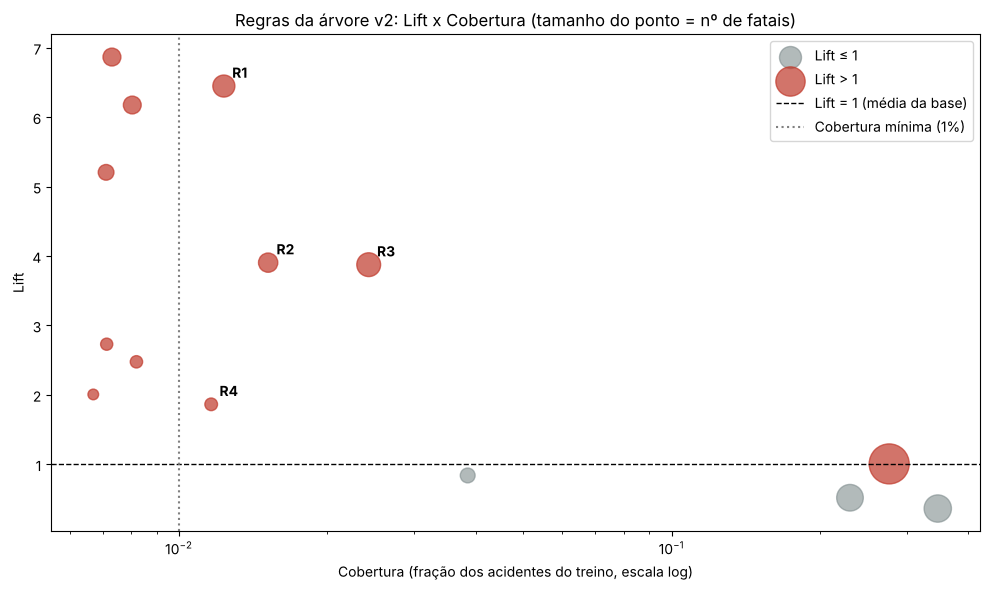

In [29]:
# Mapa das regras: força relativa (Lift) x tamanho do grupo (Cobertura)
fig, ax = plt.subplots(figsize=(10, 6))
acima = regras_v2["lift"] > 1
ax.scatter(regras_v2.loc[~acima, "cobertura"], regras_v2.loc[~acima, "lift"],
           s=regras_v2.loc[~acima, "fatais"] * 0.8 + 20, color="#7f8c8d", alpha=0.6, label="Lift ≤ 1")
ax.scatter(regras_v2.loc[acima, "cobertura"], regras_v2.loc[acima, "lift"],
           s=regras_v2.loc[acima, "fatais"] * 0.8 + 20, color="#c0392b", alpha=0.7, label="Lift > 1")
for _, r in regras_filtradas.head(5).iterrows():
    ax.annotate(f"R{r['ranking']}", (r["cobertura"], r["lift"]), textcoords="offset points",
                xytext=(6, 6), fontsize=10, fontweight="bold")
ax.axhline(1, color="black", linestyle="--", linewidth=1, label="Lift = 1 (média da base)")
ax.axvline(COBERTURA_MINIMA, color="gray", linestyle=":", label=f"Cobertura mínima ({COBERTURA_MINIMA:.0%})")
ax.set_xscale("log")
ax.set_xlabel("Cobertura (fração dos acidentes do treino, escala log)")
ax.set_ylabel("Lift")
ax.set_title("Regras da árvore v2: Lift x Cobertura (tamanho do ponto = nº de fatais)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Leitura do gráfico:** as regras mais interessantes ficam no **alto e à direita** (Lift alto e grupo grande). Pontos no alto e à esquerda têm Lift alto mas cobrem poucos casos, então pedem cautela. Pontos abaixo da linha tracejada são grupos com fatalidade abaixo da média.

> **Sua vez:** reescreva com suas palavras a interpretação das principais regras do ranking (até 5). Para cada uma, responda: (1) faz sentido frente ao que você conhece de segurança viária? (2) é estável no teste? (3) é acionável, ou seja, sugere alguma investigação ou ação? Complete as colunas `interpretacao` e `cautelas` do arquivo `resultados/regras_arvore_modulo7.csv`, que faz parte da entrega.

*Resposta:*

## Bloco 5 — Práticas avançadas

Até aqui usamos uma árvore rasa, escolhida "a dedo" para ser legível. Nesta parte investigamos com mais rigor:

1. **Complexidade:** o que acontece quando a árvore cresce demais (*overfitting*)?
2. **Validação cruzada e busca em grade:** como escolher os parâmetros sem "viciar" o teste?
3. **Poda por custo-complexidade:** outra forma de controlar o tamanho.
4. **Importância das variáveis:** quais variáveis a árvore mais usa?
5. **Engenharia de atributos:** o que muda ao incluir `tracado_via` e `br`?

### 5.1 Complexidade e overfitting

Uma árvore sem limites cresce até quase decorar o treino: cria folhas com um único acidente e regras específicas demais. No treino ela fica ótima; no teste, piora. Esse descolamento entre treino e teste é o **overfitting** (sobreajuste).

Abaixo treinamos árvores de profundidade 1 a 20, sem exigir tamanho mínimo de folha, e comparamos a PR-AUC no treino e no teste.

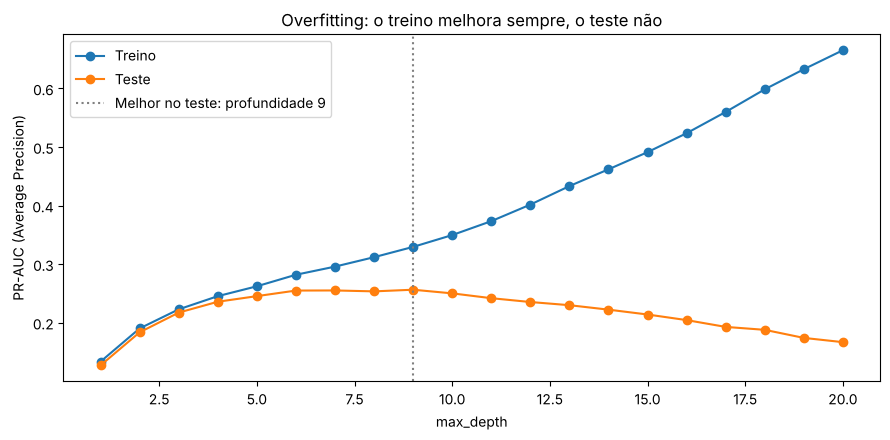

,profundidade,folhas,pr_auc_treino,pr_auc_teste
0,1,2,0.1335,0.1271
2,3,8,0.2227,0.2172
3,4,16,0.2452,0.2357
5,6,59,0.2818,0.2548
7,8,149,0.3118,0.2534
9,10,323,0.3495,0.2500
14,15,1221,0.4911,0.2139
19,20,2720,0.6652,0.1667


In [30]:
profundidades = list(range(1, 21))
resultado_prof = []
for prof in profundidades:
    modelo = criar_arvore(max_depth=prof, class_weight="balanced").fit(X_treino, y_treino)
    resultado_prof.append({
        "profundidade": prof,
        "folhas": modelo.named_steps["arvore"].get_n_leaves(),
        "pr_auc_treino": average_precision_score(y_treino, modelo.predict_proba(X_treino)[:, 1]),
        "pr_auc_teste": average_precision_score(y_teste, modelo.predict_proba(X_teste)[:, 1]),
    })
resultado_prof = pd.DataFrame(resultado_prof)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(resultado_prof["profundidade"], resultado_prof["pr_auc_treino"], marker="o", label="Treino")
ax.plot(resultado_prof["profundidade"], resultado_prof["pr_auc_teste"], marker="o", label="Teste")
melhor = resultado_prof.loc[resultado_prof["pr_auc_teste"].idxmax()]
ax.axvline(melhor["profundidade"], color="gray", linestyle=":",
           label=f"Melhor no teste: profundidade {int(melhor['profundidade'])}")
ax.set_xlabel("max_depth")
ax.set_ylabel("PR-AUC (Average Precision)")
ax.set_title("Overfitting: o treino melhora sempre, o teste não")
ax.legend()
plt.tight_layout()
plt.show()

resultado_prof.round(4).iloc[[0, 2, 3, 5, 7, 9, 14, 19]]

**Leitura:** no treino, a PR-AUC sobe sem parar. No teste, ela melhora até certo ponto e depois estabiliza ou cai, enquanto o número de folhas explode. Uma árvore com milhares de folhas não é explicável: ninguém lê milhares de regras.

O parâmetro `min_samples_leaf` é outra forma de frear a árvore. Veja o efeito numa árvore de profundidade 12:

In [31]:
resultado_folha = []
for minimo in [1, 10, 50, 100, 300, 1000, 3000]:
    modelo = criar_arvore(max_depth=12, min_samples_leaf=minimo, class_weight="balanced").fit(X_treino, y_treino)
    resultado_folha.append({
        "min_samples_leaf": minimo,
        "folhas": modelo.named_steps["arvore"].get_n_leaves(),
        "pr_auc_treino": average_precision_score(y_treino, modelo.predict_proba(X_treino)[:, 1]),
        "pr_auc_teste": average_precision_score(y_teste, modelo.predict_proba(X_teste)[:, 1]),
    })
pd.DataFrame(resultado_folha).round(4)

,min_samples_leaf,folhas,pr_auc_treino,pr_auc_teste
0,1,602,0.4016,0.2352
1,10,422,0.3746,0.2542
2,50,233,0.3283,0.2609
3,100,156,0.3059,0.2714
4,300,81,0.2790,0.2632
5,1000,39,0.2356,0.2328
6,3000,13,0.1775,0.1676


### 5.2 Validação cruzada e busca em grade (GridSearchCV)

Se testarmos dezenas de combinações de parâmetros e escolhermos a melhor **olhando o teste**, o teste deixa de ser um juiz imparcial: acabamos ajustando o modelo a ele.

A solução é a **validação cruzada estratificada** (*Stratified K-Fold*) feita **só no treino**:

```
Treino dividido em 5 partes (folds), cada uma com a mesma taxa de fatais:
Rodada 1: [VAL] [ T ] [ T ] [ T ] [ T ]
Rodada 2: [ T ] [VAL] [ T ] [ T ] [ T ]
...
Rodada 5: [ T ] [ T ] [ T ] [ T ] [VAL]
Nota final da combinação = média das 5 rodadas
```

O `GridSearchCV` repete isso para cada combinação de parâmetros e escolhe a de maior nota média. O teste continua guardado para a avaliação final. Usamos a PR-AUC (`average_precision`) como critério, porque ela foca na classe rara.

*Esta célula leva cerca de 1 minuto (48 combinações × 5 rodadas = 240 árvores).*

In [32]:
grade = {
    "arvore__max_depth": [3, 4, 5, 6, 8, 10],
    "arvore__min_samples_leaf": [50, 100, 300, 1000],
    "arvore__class_weight": [None, "balanced"],
}
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

busca = GridSearchCV(criar_arvore(), grade, scoring="average_precision", cv=validacao, n_jobs=-1)
busca.fit(X_treino, y_treino)

resultados_busca = (pd.DataFrame(busca.cv_results_)
                      .sort_values("rank_test_score")
                      [["param_arvore__max_depth", "param_arvore__min_samples_leaf",
                        "param_arvore__class_weight", "mean_test_score", "std_test_score", "rank_test_score"]]
                      .rename(columns=lambda c: c.replace("param_arvore__", "").replace("_test_score", "_pr_auc_cv")))

print("Melhor combinação:", busca.best_params_)
print(f"PR-AUC média na validação cruzada: {busca.best_score_:.4f}")
resultados_busca.head(10).round(4)

Melhor combinação: {'arvore__class_weight': 'balanced', 'arvore__max_depth': 10, 'arvore__min_samples_leaf': 100}
PR-AUC média na validação cruzada: 0.2729


,max_depth,min_samples_leaf,class_weight,mean_pr_auc_cv,std_pr_auc_cv,rank_pr_auc_cv
45,10,100,balanced,0.2729,0.0110,1
44,10,50,balanced,0.2727,0.0171,2
21,10,100,NaN,0.2719,0.0138,3
17,8,100,NaN,0.2694,0.0139,4
20,10,50,NaN,0.2690,0.0155,5
41,8,100,balanced,0.2686,0.0112,6
40,8,50,balanced,0.2686,0.0163,7
16,8,50,NaN,0.2663,0.0165,8
22,10,300,NaN,0.2640,0.0101,9
46,10,300,balanced,0.2635,0.0107,10


In [33]:
arvore_otimizada = busca.best_estimator_
print("Folhas da árvore otimizada:", arvore_otimizada.named_steps["arvore"].get_n_leaves(),
      "| Folhas da árvore v2:", modelo_v2.get_n_leaves())

tabela_metricas = pd.DataFrame([
    calcular_metricas(modelo_preguicoso, X_teste, y_teste, "Linha de base (sempre 'não fatal')"),
    calcular_metricas(arvore_v1, X_teste, y_teste, "Árvore v1 (prof. 3, sem pesos)"),
    calcular_metricas(arvore_v2, X_teste, y_teste, "Árvore v2 (prof. 4, balanced)"),
    calcular_metricas(arvore_otimizada, X_teste, y_teste, "Árvore otimizada (GridSearchCV)"),
]).round(4)
tabela_metricas

Folhas da árvore otimizada: 112 | Folhas da árvore v2: 14


,modelo,acuracia,precisao,recall,f1,roc_auc,pr_auc
0,Linha de base (sempre 'não fatal'),0.9282,0.0000,0.0000,0.0000,0.5000,0.0718
1,"Árvore v1 (prof. 3, sem pesos)",0.9282,0.0000,0.0000,0.0000,0.7214,0.2199
2,"Árvore v2 (prof. 4, balanced)",0.6462,0.1337,0.7166,0.2254,0.7455,0.2364
3,Árvore otimizada (GridSearchCV),0.7540,0.1731,0.6417,0.2726,0.7626,0.2679


**Leitura:** a árvore otimizada costuma ter PR-AUC e ROC-AUC melhores que a v2, mas com muito mais folhas. Esse é o dilema central do módulo, **desempenho contra explicabilidade**:

- para **ordenar casos** (priorizar trechos, por exemplo), a árvore otimizada é melhor;
- para **comunicar padrões** em poucas regras, a v2 é melhor.

Repare também que, com `class_weight=None`, as métricas que dependem do limiar 0,5 (precisão, recall, F1) podem continuar baixas mesmo com uma boa PR-AUC. Com a árvore sem pesos, o limiar 0,5 é alto demais para uma classe de 7%.

### 5.3 Poda por custo-complexidade (`ccp_alpha`)

Em vez de limitar a árvore **antes** de crescer (pré-poda, com `max_depth` e `min_samples_leaf`), podemos deixá-la crescer e depois **cortar** os ramos que acrescentam pouco (pós-poda). O parâmetro `ccp_alpha` define o "preço" de cada folha: quanto maior, mais ramos são cortados.

Para escolher o `ccp_alpha` sem usar o teste, separamos uma parte do treino como **validação**.

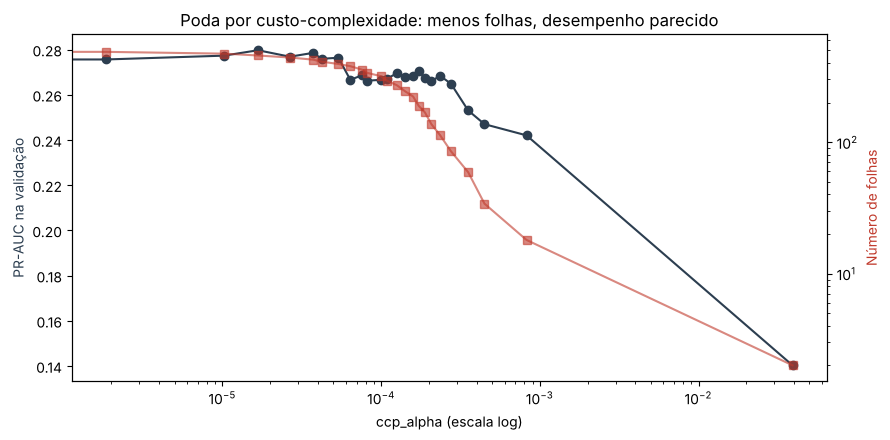

,ccp_alpha,folhas,pr_auc_validacao
0,0.000000,500,0.276704
1,0.000002,486,0.275614
2,0.000010,471,0.277307
3,0.000017,456,0.279698
4,0.000027,440,0.276835
5,0.000037,424,0.278541
6,0.000042,409,0.275911
7,0.000054,393,0.276388
8,0.000064,378,0.266591
9,0.000076,355,0.268705


In [34]:
X_subtreino, X_validacao, y_subtreino, y_validacao = train_test_split(
    X_treino, y_treino, test_size=0.25, stratify=y_treino, random_state=SEMENTE)

# Árvore grande (só com um mínimo de 50 por folha) e seu caminho de poda
arvore_grande = criar_arvore(min_samples_leaf=50, class_weight="balanced").fit(X_subtreino, y_subtreino)
prep_poda = arvore_grande.named_steps["prep"]
caminho = arvore_grande.named_steps["arvore"].cost_complexity_pruning_path(
    prep_poda.transform(X_subtreino), y_subtreino)

# Testamos 25 valores de alpha espalhados ao longo do caminho
alphas = np.unique(np.quantile(caminho.ccp_alphas[:-1], np.linspace(0, 1, 25)))
resultado_poda = []
for alpha in alphas:
    modelo = criar_arvore(min_samples_leaf=50, class_weight="balanced", ccp_alpha=alpha).fit(X_subtreino, y_subtreino)
    resultado_poda.append({
        "ccp_alpha": alpha,
        "folhas": modelo.named_steps["arvore"].get_n_leaves(),
        "pr_auc_validacao": average_precision_score(y_validacao, modelo.predict_proba(X_validacao)[:, 1]),
    })
resultado_poda = pd.DataFrame(resultado_poda)

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(resultado_poda["ccp_alpha"], resultado_poda["pr_auc_validacao"], marker="o", color="#2c3e50")
ax1.set_xscale("log")
ax1.set_xlabel("ccp_alpha (escala log)")
ax1.set_ylabel("PR-AUC na validação", color="#2c3e50")
ax2 = ax1.twinx()
ax2.plot(resultado_poda["ccp_alpha"], resultado_poda["folhas"], marker="s", color="#c0392b", alpha=0.6)
ax2.set_ylabel("Número de folhas", color="#c0392b")
ax2.set_yscale("log")
ax1.set_title("Poda por custo-complexidade: menos folhas, desempenho parecido")
plt.tight_layout()
plt.show()

resultado_poda.round(6)

**Regra prática para escolher o `ccp_alpha`:** em vez do alpha de maior PR-AUC, escolha o **maior** alpha (a árvore mais simples) cujo desempenho fique a no máximo 0,01 do melhor. Diferenças menores que isso costumam ser ruído.

In [35]:
TOLERANCIA = 0.01
melhor_pr_auc = resultado_poda["pr_auc_validacao"].max()
aceitaveis = resultado_poda[resultado_poda["pr_auc_validacao"] >= melhor_pr_auc - TOLERANCIA]
alpha_escolhido = aceitaveis["ccp_alpha"].max()
print(f"Melhor PR-AUC na validação: {melhor_pr_auc:.4f}")
print(f"ccp_alpha escolhido (árvore mais simples dentro da tolerância): {alpha_escolhido:.6f}")

# Treina com o alpha escolhido em todo o treino e avalia no teste
arvore_podada = criar_arvore(min_samples_leaf=50, class_weight="balanced",
                             ccp_alpha=alpha_escolhido).fit(X_treino, y_treino)
print("Folhas da árvore podada:", arvore_podada.named_steps["arvore"].get_n_leaves())

tabela_metricas = pd.concat([
    tabela_metricas,
    pd.DataFrame([calcular_metricas(arvore_podada, X_teste, y_teste, "Árvore podada (ccp_alpha)")]).round(4),
], ignore_index=True)
tabela_metricas

Melhor PR-AUC na validação: 0.2797
ccp_alpha escolhido (árvore mais simples dentro da tolerância): 0.000172
Folhas da árvore podada: 184


,modelo,acuracia,precisao,recall,f1,roc_auc,pr_auc
0,Linha de base (sempre 'não fatal'),0.9282,0.0000,0.0000,0.0000,0.5000,0.0718
1,"Árvore v1 (prof. 3, sem pesos)",0.9282,0.0000,0.0000,0.0000,0.7214,0.2199
2,"Árvore v2 (prof. 4, balanced)",0.6462,0.1337,0.7166,0.2254,0.7455,0.2364
3,Árvore otimizada (GridSearchCV),0.7540,0.1731,0.6417,0.2726,0.7626,0.2679
4,Árvore podada (ccp_alpha),0.7289,0.1618,0.6635,0.2601,0.7607,0.2653


> **Sua vez:** compare a árvore podada com a v2 e com a otimizada (número de folhas e PR-AUC no teste). Qual você usaria para comunicar padrões? E para priorizar casos?

### 5.4 Importância das variáveis

Há duas formas comuns de medir quais variáveis mais pesam no modelo:

| Método | Como funciona | Cuidado |
|---|---|---|
| **Importância por impureza** (`feature_importances_`) | Soma quanto cada variável reduziu o Gini em todas as divisões. | Calculada no treino; favorece variáveis com muitas categorias. |
| **Importância por permutação** | Embaralha uma variável no **teste** e mede quanto o desempenho cai. | Mais confiável; se duas variáveis dizem o mesmo, a importância se divide entre elas. |

Como o One-Hot cria várias colunas por variável, somamos as importâncias das colunas de uma mesma variável original. Importância **não** é efeito causal: só indica quanto o modelo usa aquela informação.

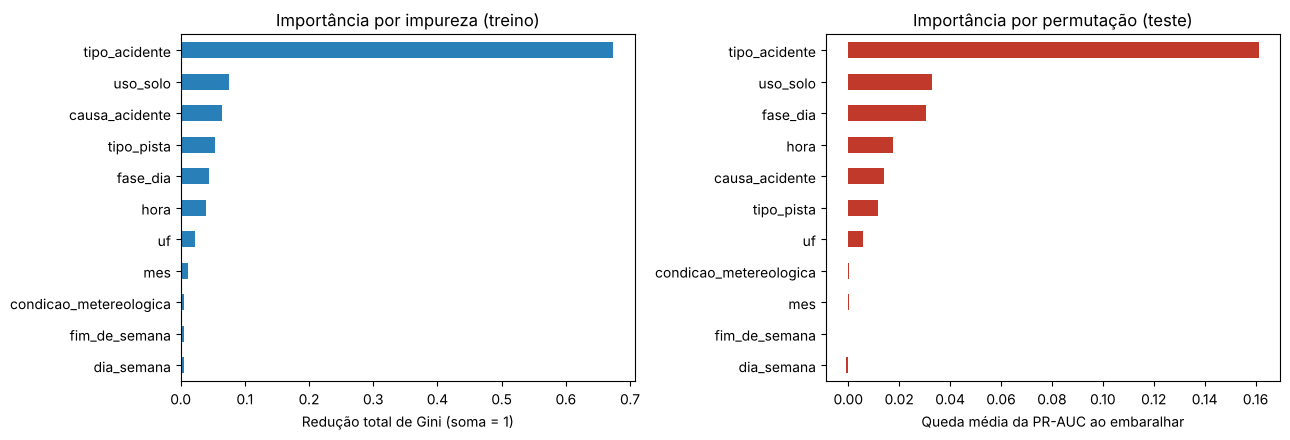

,impureza,permutacao
tipo_acidente,0.6740,0.1615
uso_solo,0.0754,0.0331
fase_dia,0.0440,0.0305
hora,0.0390,0.0174
causa_acidente,0.0647,0.0142
tipo_pista,0.0533,0.0116
uf,0.0226,0.0056
condicao_metereologica,0.0059,0.0003
mes,0.0115,0.0003
fim_de_semana,0.0048,-0.0000


In [36]:
def importancia_por_variavel(pipeline):
    nomes = pipeline.named_steps["prep"].get_feature_names_out()
    importancias = pipeline.named_steps["arvore"].feature_importances_
    variavel_original = [n.split("==")[0] for n in nomes]
    return (pd.Series(importancias, index=variavel_original)
              .groupby(level=0).sum().sort_values(ascending=False))


importancia_impureza = importancia_por_variavel(arvore_otimizada)

permutacao = permutation_importance(arvore_otimizada, X_teste, y_teste, scoring="average_precision",
                                    n_repeats=5, random_state=SEMENTE, n_jobs=-1)
importancia_permutacao = (pd.Series(permutacao.importances_mean, index=X_teste.columns)
                            .sort_values(ascending=False))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
importancia_impureza.sort_values().plot.barh(ax=eixos[0], color="#2980b9")
eixos[0].set_title("Importância por impureza (treino)")
eixos[0].set_xlabel("Redução total de Gini (soma = 1)")
importancia_permutacao.sort_values().plot.barh(ax=eixos[1], color="#c0392b")
eixos[1].set_title("Importância por permutação (teste)")
eixos[1].set_xlabel("Queda média da PR-AUC ao embaralhar")
plt.tight_layout()
plt.show()

pd.DataFrame({"impureza": importancia_impureza, "permutacao": importancia_permutacao}).sort_values(
    "permutacao", ascending=False).round(4)

> **Sua vez:** as duas medidas concordam sobre as 3 variáveis mais importantes? As variáveis mais importantes aparecem nas regras da árvore v2? Alguma variável tem importância perto de zero e poderia sair do modelo?

*Resposta:*

### 5.5 Engenharia de atributos: `tracado_via` e `br`

Na auditoria deixamos duas variáveis de fora por questões de formato:

- `tracado_via` está gravada como texto de lista, por exemplo `"['RETA', 'DECLIVE']"`, com centenas de combinações. Vamos transformá-la em **indicadores 0/1**, um por elemento de traçado (`tracado_reta`, `tracado_curva`, ...).
- `br_formatada` tem 115 categorias. Vamos manter as 20 BRs com mais acidentes e agrupar o resto em `OUTRAS`.

In [37]:
def tracado_para_lista(valor):
    # "['RETA', 'DECLIVE']" -> ['RETA', 'DECLIVE']; valores fora do padrão viram lista de 1 elemento
    try:
        itens = ast.literal_eval(str(valor))
        if isinstance(itens, (list, tuple)):
            return [str(i).strip().upper() for i in itens]
    except (ValueError, SyntaxError):
        pass
    return [str(valor).strip().upper()]


def nome_coluna(texto):
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("utf-8")
    return "tracado_" + texto.lower().replace(" ", "_").replace("/", "_")


listas_tracado = df["tracado_via"].apply(tracado_para_lista)
frequencia_elementos = pd.Series([e for lista in listas_tracado for e in lista]).value_counts()
print("Elementos de traçado encontrados (acidentes que contêm cada um):")
display(frequencia_elementos.to_frame("acidentes"))

# Cria um indicador 0/1 para cada elemento com pelo menos 500 ocorrências
elementos_usados = frequencia_elementos[frequencia_elementos >= 500].index
colunas_tracado = []
for elemento in elementos_usados:
    coluna = nome_coluna(elemento)
    df[coluna] = listas_tracado.apply(lambda lista, e=elemento: int(e in lista))
    colunas_tracado.append(coluna)

# BR: 20 mais frequentes + OUTRAS
top_brs = df["br_formatada"].value_counts().head(20).index
df["br_top20"] = df["br_formatada"].where(df["br_formatada"].isin(top_brs), "OUTRAS")

print("Indicadores criados:", colunas_tracado)

# Taxa de fatalidade quando cada elemento de traçado está presente
risco_tracado = pd.DataFrame([
    {"indicador": c,
     "acidentes_com_elemento": int(df[c].sum()),
     "taxa_fatal": round(df.loc[df[c] == 1, "acidente_fatal"].mean(), 4),
     "lift": round(df.loc[df[c] == 1, "acidente_fatal"].mean() / TAXA_GLOBAL, 2)}
    for c in colunas_tracado
]).sort_values("lift", ascending=False)
risco_tracado

Elementos de traçado encontrados (acidentes que contêm cada um):


,acidentes
RETA,53014
CURVA,13140
DECLIVE,7912
ACLIVE,6057
INTERSEÇÃO DE VIAS,5323
ROTATÓRIA,1929
RETORNO REGULAMENTADO,1894
EM OBRAS,1732
VIADUTO,1263
PONTE,820


Indicadores criados: ['tracado_reta', 'tracado_curva', 'tracado_declive', 'tracado_aclive', 'tracado_intersecao_de_vias', 'tracado_rotatoria', 'tracado_retorno_regulamentado', 'tracado_em_obras', 'tracado_viaduto', 'tracado_ponte']


,indicador,acidentes_com_elemento,taxa_fatal,lift
9,tracado_ponte,820,0.1049,1.46
2,tracado_declive,7912,0.0978,1.36
3,tracado_aclive,6057,0.0905,1.26
1,tracado_curva,13140,0.0855,1.19
0,tracado_reta,53014,0.0732,1.02
7,tracado_em_obras,1732,0.0612,0.85
8,tracado_viaduto,1263,0.0435,0.61
4,tracado_intersecao_de_vias,5323,0.0346,0.48
6,tracado_retorno_regulamentado,1894,0.0327,0.46
5,tracado_rotatoria,1929,0.0202,0.28


In [38]:
CATEGORICAS_EXT = COLUNAS_CATEGORICAS + ["br_top20"]
NUMERICAS_EXT = COLUNAS_NUMERICAS + colunas_tracado

# Mesmas linhas de treino e teste usadas até aqui (comparação justa)
X_ext = df[CATEGORICAS_EXT + NUMERICAS_EXT]
X_treino_ext, X_teste_ext = X_ext.loc[X_treino.index], X_ext.loc[X_teste.index]


def criar_arvore_ext(**parametros):
    return Pipeline([
        ("prep", criar_preprocessador(CATEGORICAS_EXT, NUMERICAS_EXT)),
        ("arvore", DecisionTreeClassifier(random_state=SEMENTE, **parametros)),
    ])


parametros_v2 = {"max_depth": 4, "min_samples_leaf": 300, "class_weight": "balanced"}
parametros_otim = {k.replace("arvore__", ""): v for k, v in busca.best_params_.items()}

comparacao_ext = []
for rotulo, fabrica, X_tr in [("Original", criar_arvore, X_treino), ("Com tracado + BR", criar_arvore_ext, X_treino_ext)]:
    for nome_param, params in [("v2 (prof. 4)", parametros_v2), ("otimizada", parametros_otim)]:
        cv = cross_validate(fabrica(**params), X_tr, y_treino, cv=validacao,
                            scoring="average_precision", n_jobs=-1)
        comparacao_ext.append({"atributos": rotulo, "arvore": nome_param,
                               "pr_auc_cv_media": cv["test_score"].mean(),
                               "pr_auc_cv_desvio": cv["test_score"].std()})
pd.DataFrame(comparacao_ext).round(4)

,atributos,arvore,pr_auc_cv_media,pr_auc_cv_desvio
0,Original,v2 (prof. 4),0.2405,0.0123
1,Original,otimizada,0.2729,0.0110
2,Com tracado + BR,v2 (prof. 4),0.2404,0.0123
3,Com tracado + BR,otimizada,0.2768,0.0081


In [39]:
# Regras da árvore v2 treinada com os atributos novos
arvore_v2_ext = criar_arvore_ext(**parametros_v2).fit(X_treino_ext, y_treino)
regras_v2_ext = tabela_de_regras(arvore_v2_ext, X_treino_ext, y_treino, X_teste_ext, y_teste)
regras_v2_ext[(regras_v2_ext["cobertura"] >= COBERTURA_MINIMA) & (regras_v2_ext["lift"] > 1)][
    ["regra", "registros", "fatais", "cobertura", "confianca", "lift", "lift_teste"]].head(8).round(4)

,regra,registros,fatais,cobertura,confianca,lift,lift_teste
1,"tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia é AMANHECER, ANOITECER ou PLENA NOITE E uso_solo = NÃO",626,290,0.0123,0.4633,6.4490,6.3963
4,"tipo_acidente = ATROPELAMENTO DE PEDESTRE E fase_dia é AMANHECER, ANOITECER ou PLENA NOITE E uso_solo = SIM",770,216,0.0152,0.2805,3.9051,4.0268
5,tipo_acidente = COLISÃO FRONTAL E uso_solo = NÃO E causa_acidente ≠ TRANSITAR NA CONTRAMÃO E hora ≥ 8,1232,343,0.0243,0.2784,3.8757,3.8958
9,tipo_acidente = COLISÃO FRONTAL E uso_solo = SIM E causa_acidente ≠ TRANSITAR NA CONTRAMÃO,590,79,0.0116,0.1339,1.8640,1.5358
10,tipo_acidente não é COLISÃO FRONTAL nem ATROPELAMENTO DE PEDESTRE E uso_solo = NÃO E tipo_pista = SIMPLES,14036,1014,0.2765,0.0722,1.0057,1.0184


**Leitura:** compare a PR-AUC média da validação cruzada com e sem os atributos novos. Se o ganho for menor que o desvio entre as rodadas, ele pode ser ruído. Veja também se `tracado_*` ou `br_top20` aparecem nas regras com Lift alto.

> **Sua vez:** vale a pena manter os novos atributos? Considere o ganho de desempenho **e** o efeito na clareza das regras.

*Resposta:*

## Bloco 6 — Comparar a árvore com a análise exploratória (EDA)

A EDA do Módulo 5 olhou as variáveis **uma de cada vez** (e alguns cruzamentos). A árvore olha **combinações**. As duas leituras se complementam:

- padrão que aparece **nas duas**: merece atenção;
- padrão que aparece **só na árvore**: novo, mas precisa de cautela;
- padrão que aparece **só na EDA**: pode estar "escondido" por outra variável que a árvore preferiu usar.

### Atividade prática 5 — Quadro EDA x árvore

Primeiro, recuperamos os achados univariados da EDA: a categoria de maior Lift em cada variável, com pelo menos 300 acidentes. São os mesmos cálculos dos arquivos `resultados/bivariada_*.csv` do Módulo 5.

In [40]:
VARIAVEIS_EDA = ["tipo_acidente", "causa_acidente", "uf", "fase_dia",
                 "tipo_pista", "condicao_metereologica", "uso_solo", "dia_semana"]

principais_regras = regras_filtradas.head(5)

quadro = []
for variavel in VARIAVEIS_EDA:
    risco = tabela_risco(df, variavel, min_registros=300).sort_values("lift", ascending=False)
    topo = risco.iloc[0]
    categoria = topo[variavel]
    # A regra usa a MESMA categoria da EDA (condição positiva "variavel = categoria")?
    mesma_categoria = principais_regras[principais_regras["regra"].str.contains(f"{variavel} = {categoria}", regex=False)]
    # Ou usa a variável com outra condição (outra categoria, "≠", faixa numérica)?
    mesma_variavel = principais_regras[principais_regras["regra"].str.contains(f"{variavel} ", regex=False)]
    if not mesma_categoria.empty:
        leitura, regras_rel = "Convergência: a categoria aparece isolada (EDA) e em combinação (árvore)", mesma_categoria
    elif not mesma_variavel.empty:
        leitura, regras_rel = "Convergência parcial: a variável aparece nas regras, com outra condição", mesma_variavel
    else:
        leitura, regras_rel = "Só na EDA: pode estar coberta por outra variável na árvore", mesma_variavel
    quadro.append({
        "variavel": variavel,
        "achado_eda": (f"{categoria}: taxa {topo['taxa_fatal']:.1%}, "
                       f"Lift {topo['lift']:.2f} ({int(topo['registros'])} acidentes)"),
        "regras_relacionadas": ", ".join(f"R{i}" for i in regras_rel["ranking"]) or "-",
        "leitura_conjunta": leitura,
        "cautela_metodologica": "",
    })
quadro_eda_arvore = pd.DataFrame(quadro)
quadro_eda_arvore.to_csv(PASTA_RESULTADOS / "quadro_eda_x_arvore_modulo7.csv",
                         sep=SEPARADOR, encoding=ENCODING, index=False)
quadro_eda_arvore

,variavel,achado_eda,regras_relacionadas,leitura_conjunta,cautela_metodologica
0,tipo_acidente,"ATROPELAMENTO DE PEDESTRE: taxa 29.5%, Lift 4.11 (3057 acidentes)","R1, R2",Convergência: a categoria aparece isolada (EDA) e em combinação (árvore),
1,causa_acidente,"PEDESTRE ANDAVA NA PISTA: taxa 41.2%, Lift 5.74 (606 acidentes)","R3, R4","Convergência parcial: a variável aparece nas regras, com outra condição",
2,uf,"MA: taxa 18.7%, Lift 2.60 (1262 acidentes)",-,Só na EDA: pode estar coberta por outra variável na árvore,
3,fase_dia,"AMANHECER: taxa 11.2%, Lift 1.56 (3447 acidentes)","R1, R2","Convergência parcial: a variável aparece nas regras, com outra condição",
4,tipo_pista,"SIMPLES: taxa 9.9%, Lift 1.37 (34733 acidentes)",-,Só na EDA: pode estar coberta por outra variável na árvore,
5,condicao_metereologica,"NEVOEIRO/NEBLINA: taxa 10.8%, Lift 1.51 (553 acidentes)",-,Só na EDA: pode estar coberta por outra variável na árvore,
6,uso_solo,"NÃO: taxa 9.1%, Lift 1.27 (41444 acidentes)","R1, R3",Convergência: a categoria aparece isolada (EDA) e em combinação (árvore),
7,dia_semana,"DOMINGO: taxa 8.9%, Lift 1.23 (11470 acidentes)",-,Só na EDA: pode estar coberta por outra variável na árvore,


> **Sua vez:** complete a coluna `cautela_metodologica` (no arquivo `resultados/quadro_eda_x_arvore_modulo7.csv` ou numa tabela própria) e escreva uma síntese de 5 a 10 linhas respondendo:
>
> 1. Quais padrões se repetem na EDA e na árvore?
> 2. Quais padrões são novos, ou seja, só aparecem como combinação na árvore?
> 3. Quais padrões parecem frágeis (grupo pequeno, instáveis no teste, categorias agrupadas)?
> 4. Quais merecem investigação adicional no Módulo 8?
>
> Diferencie sempre **associação** (o que os dados mostram), **hipótese** (uma explicação possível) e **causalidade** (que este estudo não prova).

*Síntese:*

## Bloco 7 — Limites da explicabilidade

A árvore ajuda a explicar padrões, mas:

- **não prova causalidade**: mostra associações nos dados observados;
- **depende das variáveis disponíveis**: fatores ausentes (velocidade, tipo de veículo, uso de cinto, tempo de socorro) podem explicar parte dos padrões;
- **pode refletir vieses de registro**: causa e tipo são registrados pela PRF depois do acidente, com algum grau de subjetividade;
- **pode mudar com novos dados**: árvores são instáveis, e uma pequena mudança na base pode trocar a primeira pergunta;
- **simplifica relações complexas** em cortes do tipo sim/não;
- **gera regras frágeis em subgrupos pequenos**, por isso a Cobertura mínima e a checagem no teste.

### Linguagem: associação, não causa

| Evitar (causal) | Preferir (analítico) |
|---|---|
| "Colisões frontais causam mortes." | "Colisões frontais estão associadas a uma proporção de acidentes fatais cerca de 4 vezes maior que a média da base." |
| "Pista simples mata mais." | "Nos acidentes em pista simples, a proporção de fatais é maior do que em pista dupla, nos dados de 2025." |
| "Se reduzirmos acidentes à noite, as mortes vão cair." | "A regra noturna indica um grupo prioritário para investigação; o efeito de uma intervenção precisaria de outro tipo de estudo." |

> **Sua vez:** reescreva em linguagem analítica três frases causais que você ou sua equipe usaram em módulos anteriores.

*Resposta:*

### Resumo das métricas dos modelos

A tabela abaixo é salva em `resultados/metricas_modelos_modulo7.csv` para a entrega.

In [41]:
tabela_metricas.to_csv(PASTA_RESULTADOS / "metricas_modelos_modulo7.csv",
                       sep=SEPARADOR, encoding=ENCODING, index=False, decimal=",")

print("Arquivos gerados em", PASTA_RESULTADOS)
for arquivo in ["auditoria_base_modelavel_modulo7.csv", "regras_arvore_modulo7.csv",
                "quadro_eda_x_arvore_modulo7.csv", "metricas_modelos_modulo7.csv"]:
    caminho = PASTA_RESULTADOS / arquivo
    print(f"  {'OK ' if caminho.exists() else 'FALTA'}  {arquivo}")
tabela_metricas

Arquivos gerados em /home/claude/dansoaresfarias/fap-2026-analisedados/Projeto_PRF/resultados
  OK   auditoria_base_modelavel_modulo7.csv
  OK   regras_arvore_modulo7.csv
  OK   quadro_eda_x_arvore_modulo7.csv
  OK   metricas_modelos_modulo7.csv


,modelo,acuracia,precisao,recall,f1,roc_auc,pr_auc
0,Linha de base (sempre 'não fatal'),0.9282,0.0000,0.0000,0.0000,0.5000,0.0718
1,"Árvore v1 (prof. 3, sem pesos)",0.9282,0.0000,0.0000,0.0000,0.7214,0.2199
2,"Árvore v2 (prof. 4, balanced)",0.6462,0.1337,0.7166,0.2254,0.7455,0.2364
3,Árvore otimizada (GridSearchCV),0.7540,0.1731,0.6417,0.2726,0.7626,0.2679
4,Árvore podada (ccp_alpha),0.7289,0.1618,0.6635,0.2601,0.7607,0.2653


## Checklist da entrega do Módulo 7

- [ ] Variável `acidente_fatal` conferida (binária, 1 quando `mortos >= 1`)
- [ ] Base modelável sem vazamento (Atividade 1, `auditoria_base_modelavel_modulo7.csv`)
- [ ] Variáveis explicativas justificadas
- [ ] Separação X/y, codificação e treino/teste estratificado
- [ ] Árvore treinada com profundidade controlada e visualizada (Atividade 2)
- [ ] Métricas calculadas **e interpretadas**, não apenas a acurácia (Atividade 3)
- [ ] Regras extraídas e ranqueadas, com Cobertura, Confiança e Lift (Atividade 4, `regras_arvore_modulo7.csv`)
- [ ] Regras filtradas por Cobertura mínima e conferidas no teste
- [ ] Quadro comparativo EDA x árvore com síntese (Atividade 5)
- [ ] Limitações metodológicas declaradas
- [ ] Todas as células **Sua vez** respondidas

**Erros comuns:** usar `mortos` como explicativa; relatar só acurácia; confundir frequência com risco; escolher regra só pelo Lift; ignorar a Cobertura; afirmar causalidade.

**Próximos passos:** no Módulo 8, as regras viram linguagem executiva (relatório e storytelling). No Módulo 9, entram no diagnóstico analítico final.

## Desafios (do básico ao avançado)

1. **Básico:** troque `max_depth=4` por 3 e por 5 na árvore v2. O que acontece com o número de regras e com o Lift das 5 principais?
2. **Básico:** mude a `COBERTURA_MINIMA` para 0,5% e para 3%, e o `LIFT_MINIMO` para 1,5. Quais regras entram e saem do ranking?
3. **Intermediário:** treine a árvore v2 com `criterion="entropy"` e compare as regras com as do Gini.
4. **Intermediário:** recalcule a tabela de regras usando `X_teste` no lugar do treino (troque a ordem dos argumentos em `tabela_de_regras`). Quais regras se mantêm no topo?
5. **Avançado:** crie uma árvore só com variáveis conhecidas **antes** do acidente (sem `causa_acidente` e `tipo_acidente`). Quais fatores aparecem? O desempenho cai muito? Discuta o que isso diz sobre a pergunta do projeto.
6. **Avançado:** treine a árvore v2 com 5 sementes diferentes em `train_test_split` e verifique se a primeira pergunta da árvore e as 3 regras principais se repetem. O que isso diz sobre a estabilidade das árvores?